# Root-length prediction — Clean CV Pipeline to Individual root segmentation

This notebook is the cleaned version of the Root-length prediction work completed so far.

Pipeline:

**Raw Kaggle image → Petri crop → exact U-Net root segmentation root inference → V5.1 root starts → Individual root segmentation individual root assignment**

Failed experiments and diagnostics have been removed. Run this notebook **top to bottom**.


In [1]:
# ============================================================
# 1. SETUP — PATHS, DATA AND OUTPUT FOLDERS
# ============================================================

from pathlib import Path
import zipfile

BASE_DIR = Path("/home/y2a")
KAGGLE_ZIP = BASE_DIR / "Kaggle (1).zip"
ROOT_MODEL_PATH = BASE_DIR / "NikaSoleimanzadeh_244258_unet_model_512px.h5"

# Fresh folder so old experiments cannot contaminate this run.
PIPELINE_DIR = BASE_DIR / "task8_clean_pipeline"
DATA_DIR = PIPELINE_DIR / "data"
OUTPUT_DIR = PIPELINE_DIR / "outputs"

assert KAGGLE_ZIP.exists(), f"Kaggle ZIP missing: {KAGGLE_ZIP}"
assert ROOT_MODEL_PATH.exists(), f"Root model missing: {ROOT_MODEL_PATH}"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(KAGGLE_ZIP, "r") as z:
    z.extractall(DATA_DIR)

TEST_IMAGE_DIR = DATA_DIR / "Kaggle"
test_images = sorted(TEST_IMAGE_DIR.glob("*.png"))

assert TEST_IMAGE_DIR.exists(), f"Image folder missing: {TEST_IMAGE_DIR}"
assert len(test_images) > 0, "No PNG test images found."

print("Images found:", len(test_images))
print("Model:", ROOT_MODEL_PATH)
print("Outputs:", OUTPUT_DIR)


Images found: 19
Model: /home/y2a/NikaSoleimanzadeh_244258_unet_model_512px.h5
Outputs: /home/y2a/task8_clean_pipeline/outputs


In [2]:
# ============================================================
# U-Net root segmentation — LOAD MODEL WITH KERAS 3, NOT LEGACY TF_KERAS
# ============================================================

import os
import tensorflow as tf

import tf_keras as keras
from tf_keras import backend as K
from tf_keras import layers

# Must happen BEFORE importing TensorFlow.
os.environ.pop("TF_USE_LEGACY_KERAS", None)

from pathlib import Path

import tensorflow as tf
import tf_keras as keras


ROOT_MODEL_PATH = Path(
    "/home/y2a/NikaSoleimanzadeh_244258_unet_model_512px.h5"
)

assert ROOT_MODEL_PATH.exists(), (
    f"Model not found: {ROOT_MODEL_PATH}"
)


print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("Keras location:", keras.__file__)


custom_objects = {
    "RootSeg>GroupNormalization":
        keras.layers.GroupNormalization,

    "GroupNormalization":
        keras.layers.GroupNormalization,
}


root_model = keras.models.load_model(
    str(ROOT_MODEL_PATH),
    custom_objects=custom_objects,
    compile=False
)


print()
print("✅ MODEL LOADED")
print("Input :", root_model.input_shape)
print("Output:", root_model.output_shape)

assert root_model.input_shape == (
    None,
    512,
    512,
    1
)

assert root_model.output_shape == (
    None,
    512,
    512,
    1
)

I0000 00:00:1791562813.892267   26069 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791562813.936524   26069 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791562814.969831   26069 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
Keras: 2.21.0
Keras location: /usr/local/lib/python3.12/dist-packages/tf_keras/__init__.py


W0000 00:00:1791562815.952337   26069 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1791562815.953344   26069 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 43487 MB memory:  -> device: 0, name: NVIDIA L40S, pci bus id: 0000:21:00.0, compute capability: 8.9



✅ MODEL LOADED
Input : (None, 512, 512, 1)
Output: (None, 512, 512, 1)


In [2]:
import tensorflow as tf
import tf_keras as keras

print("TensorFlow:", tf.__version__)
print("tf_keras:", keras.__version__)
print("TensorFlow path:", tf.__file__)
print("tf_keras path:", keras.__file__)

TensorFlow: 2.21.0
tf_keras: 2.21.0
TensorFlow path: /usr/local/lib/python3.12/dist-packages/tensorflow/__init__.py
tf_keras path: /usr/local/lib/python3.12/dist-packages/tf_keras/__init__.py


In [3]:
import numpy as np
import scipy
import sklearn
import cv2
import tensorflow as tf
import keras

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("sklearn:", sklearn.__version__)
print("OpenCV:", cv2.__version__)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

NumPy: 1.26.4
SciPy: 1.14.1
sklearn: 1.5.2
OpenCV: 4.10.0
TensorFlow: 2.21.0
Keras: 3.15.1


## U-Net root segmentation — Root segmentation

The model is loaded and inferred using the same `tf_keras`, custom `GroupNormalization`, Petri extraction, reflected padding, 512×512 patches, stride 256 and overlap averaging as the successful U-Net root segmentation inference notebook.


In [4]:
# ============================================================
# 2. U-Net root segmentation — MODEL + ORIGINAL INFERENCE FUNCTIONS
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras as k3

from pathlib import Path


ROOT_MODEL_PATH = Path(
    "/home/y2a/NikaSoleimanzadeh_244258_unet_model_512px.h5"
)

assert ROOT_MODEL_PATH.exists(), (
    f"Model not found: {ROOT_MODEL_PATH}"
)

print("TensorFlow:", tf.__version__)
print("Keras:", k3.__version__)


# ------------------------------------------------------------
# Compatibility wrapper
#
# The saved H5 contains:
# Conv2DTranspose(... groups=1)
#
# groups=1 means ordinary Conv2DTranspose behaviour.
# This wrapper simply discards that unsupported metadata field.
# THE ORIGINAL MODEL FILE AND WEIGHTS ARE NOT MODIFIED.
# ------------------------------------------------------------

class CompatibleConv2DTranspose(
    k3.layers.Conv2DTranspose
):

    def __init__(
        self,
        *args,
        groups=1,
        **kwargs
    ):

        if groups != 1:
            raise ValueError(
                "This compatibility loader only supports groups=1."
            )

        super().__init__(
            *args,
            **kwargs
        )


custom_objects = {
    "Conv2DTranspose":
        CompatibleConv2DTranspose,

    "GroupNormalization":
        k3.layers.GroupNormalization,

    "RootSeg>GroupNormalization":
        k3.layers.GroupNormalization,
}


root_model = k3.models.load_model(
    str(ROOT_MODEL_PATH),
    custom_objects=custom_objects,
    compile=False
)


print()
print("✅ MODEL LOADED")
print("Input :", root_model.input_shape)
print("Output:", root_model.output_shape)

assert root_model.input_shape == (
    None,
    512,
    512,
    1
)

assert root_model.output_shape == (
    None,
    512,
    512,
    1
)


# ============================================================
# ORIGINAL U-Net root segmentation INFERENCE FUNCTIONS
# ============================================================

def find_petri_dish(image):

    blurred = cv2.GaussianBlur(
        image,
        (5, 5),
        0
    )

    _, binary = cv2.threshold(
        blurred,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if len(contours) == 0:
        raise RuntimeError(
            "Could not detect the Petri dish."
        )

    dish_contour = max(
        contours,
        key=cv2.contourArea
    )

    x, y, w, h = cv2.boundingRect(
        dish_contour
    )

    SIDE_INSET = 20

    x = x + SIDE_INSET
    w = w - (2 * SIDE_INSET)

    return x, y, w, h


def pad_for_patches(
    image,
    patch_size=512,
    stride=256
):

    h, w = image.shape

    if h <= patch_size:

        pad_h = patch_size - h

    else:

        remainder_h = (
            h - patch_size
        ) % stride

        pad_h = (
            0
            if remainder_h == 0
            else stride - remainder_h
        )

    if w <= patch_size:

        pad_w = patch_size - w

    else:

        remainder_w = (
            w - patch_size
        ) % stride

        pad_w = (
            0
            if remainder_w == 0
            else stride - remainder_w
        )

    padded = cv2.copyMakeBorder(
        image,
        0,
        pad_h,
        0,
        pad_w,
        cv2.BORDER_REFLECT
    )

    return padded


def tiled_prediction(
    model,
    image,
    patch_size=512,
    stride=256,
    batch_size=4
):

    image_normalized = (
        image.astype(np.float32)
        /
        255.0
    )

    h, w = image_normalized.shape

    prediction_sum = np.zeros(
        (h, w),
        dtype=np.float32
    )

    prediction_count = np.zeros(
        (h, w),
        dtype=np.float32
    )

    patches = []
    coordinates = []


    def predict_batch(
        patch_batch,
        coordinate_batch
    ):

        if len(patch_batch) == 0:
            return

        batch = np.stack(
            patch_batch,
            axis=0
        )

        predictions = model.predict(
            batch,
            verbose=0
        )[..., 0]

        for prediction, (y, x) in zip(
            predictions,
            coordinate_batch
        ):

            prediction_sum[
                y:y + patch_size,
                x:x + patch_size
            ] += prediction

            prediction_count[
                y:y + patch_size,
                x:x + patch_size
            ] += 1


    for y in range(
        0,
        h - patch_size + 1,
        stride
    ):

        for x in range(
            0,
            w - patch_size + 1,
            stride
        ):

            patch = image_normalized[
                y:y + patch_size,
                x:x + patch_size
            ]

            patch = patch[
                ...,
                np.newaxis
            ]

            patches.append(
                patch
            )

            coordinates.append(
                (y, x)
            )

            if len(patches) == batch_size:

                predict_batch(
                    patches,
                    coordinates
                )

                patches = []
                coordinates = []

    predict_batch(
        patches,
        coordinates
    )

    probability_map = (
        prediction_sum
        /
        np.maximum(
            prediction_count,
            1
        )
    )

    return probability_map


print("✅ Task 5 inference functions ready.")

TensorFlow: 2.21.0
Keras: 3.15.1

✅ MODEL LOADED
Input : (None, 512, 512, 1)
Output: (None, 512, 512, 1)
✅ Task 5 inference functions ready.


In [ ]:
# ============================================================
# 3. U-Net root segmentation — RUN EXACT ORIGINAL INFERENCE ON ALL RAW IMAGES
# ============================================================

PATCH_SIZE = 512
STRIDE = 256
BATCH_SIZE = 4
ROOT_THRESHOLD = 0.50

PETRI_DIR = OUTPUT_DIR / "01_petri_crops"
PROB_DIR = OUTPUT_DIR / "02_root_probabilities"
MASK_DIR = OUTPUT_DIR / "03_root_masks"

PETRI_DIR.mkdir(parents=True, exist_ok=True)
PROB_DIR.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)

petri_images = []
task5_results = {}
crop_records = []

for i, raw_path in enumerate(test_images, start=1):

    stem = raw_path.stem
    print(f"[{i:02d}/{len(test_images)}] {stem}")

    gray = cv2.imread(str(raw_path), cv2.IMREAD_GRAYSCALE)
    bgr = cv2.imread(str(raw_path), cv2.IMREAD_COLOR)

    assert gray is not None, f"Could not read {raw_path}"
    assert bgr is not None, f"Could not read {raw_path}"

    # Exact Petri extraction used in the successful U-Net root segmentation notebook.
    x, y, dish_w, dish_h = find_petri_dish(gray)

    petri_gray = gray[y:y + dish_h, x:x + dish_w]
    petri_bgr = bgr[y:y + dish_h, x:x + dish_w]

    petri_path = PETRI_DIR / f"{stem}_petri.png"
    assert cv2.imwrite(str(petri_path), petri_bgr)
    petri_images.append(petri_path)

    # Exact reflected padding + stride-256 overlap averaging.
    padded = pad_for_patches(
        petri_gray,
        patch_size=PATCH_SIZE,
        stride=STRIDE
    )

    probability_padded = tiled_prediction(
        model=root_model,
        image=padded,
        patch_size=PATCH_SIZE,
        stride=STRIDE,
        batch_size=BATCH_SIZE
    )

    petri_h, petri_w = petri_gray.shape
    probability = probability_padded[:petri_h, :petri_w]

    predicted_mask = (
        probability >= ROOT_THRESHOLD
    ).astype(np.uint8)

    probability_path = PROB_DIR / f"{stem}_root_probability.npy"
    mask_path = MASK_DIR / f"{stem}_root_mask.png"

    np.save(probability_path, probability.astype(np.float32))
    assert cv2.imwrite(str(mask_path), predicted_mask * 255)

    crop_records.append({
        "image": raw_path.name,
        "x": x,
        "y": y,
        "width": dish_w,
        "height": dish_h
    })

    task5_results[stem] = {
        "probability": probability,
        "mask": predicted_mask,
        "bbox": (x, y, dish_w, dish_h)
    }

crop_df = pd.DataFrame(crop_records)
crop_df.to_csv(OUTPUT_DIR / "petri_crop_metadata.csv", index=False)

print()
print("✅ Task 5 inference complete.")


In [7]:
import pandas as pd

crop_df = pd.DataFrame(crop_records)

crop_df.to_csv(
    OUTPUT_DIR / "petri_crop_metadata.csv",
    index=False
)

print("✅ Metadata saved.")
print("Images processed:", len(task5_results))

assert len(task5_results) == len(test_images)

✅ Metadata saved.
Images processed: 19


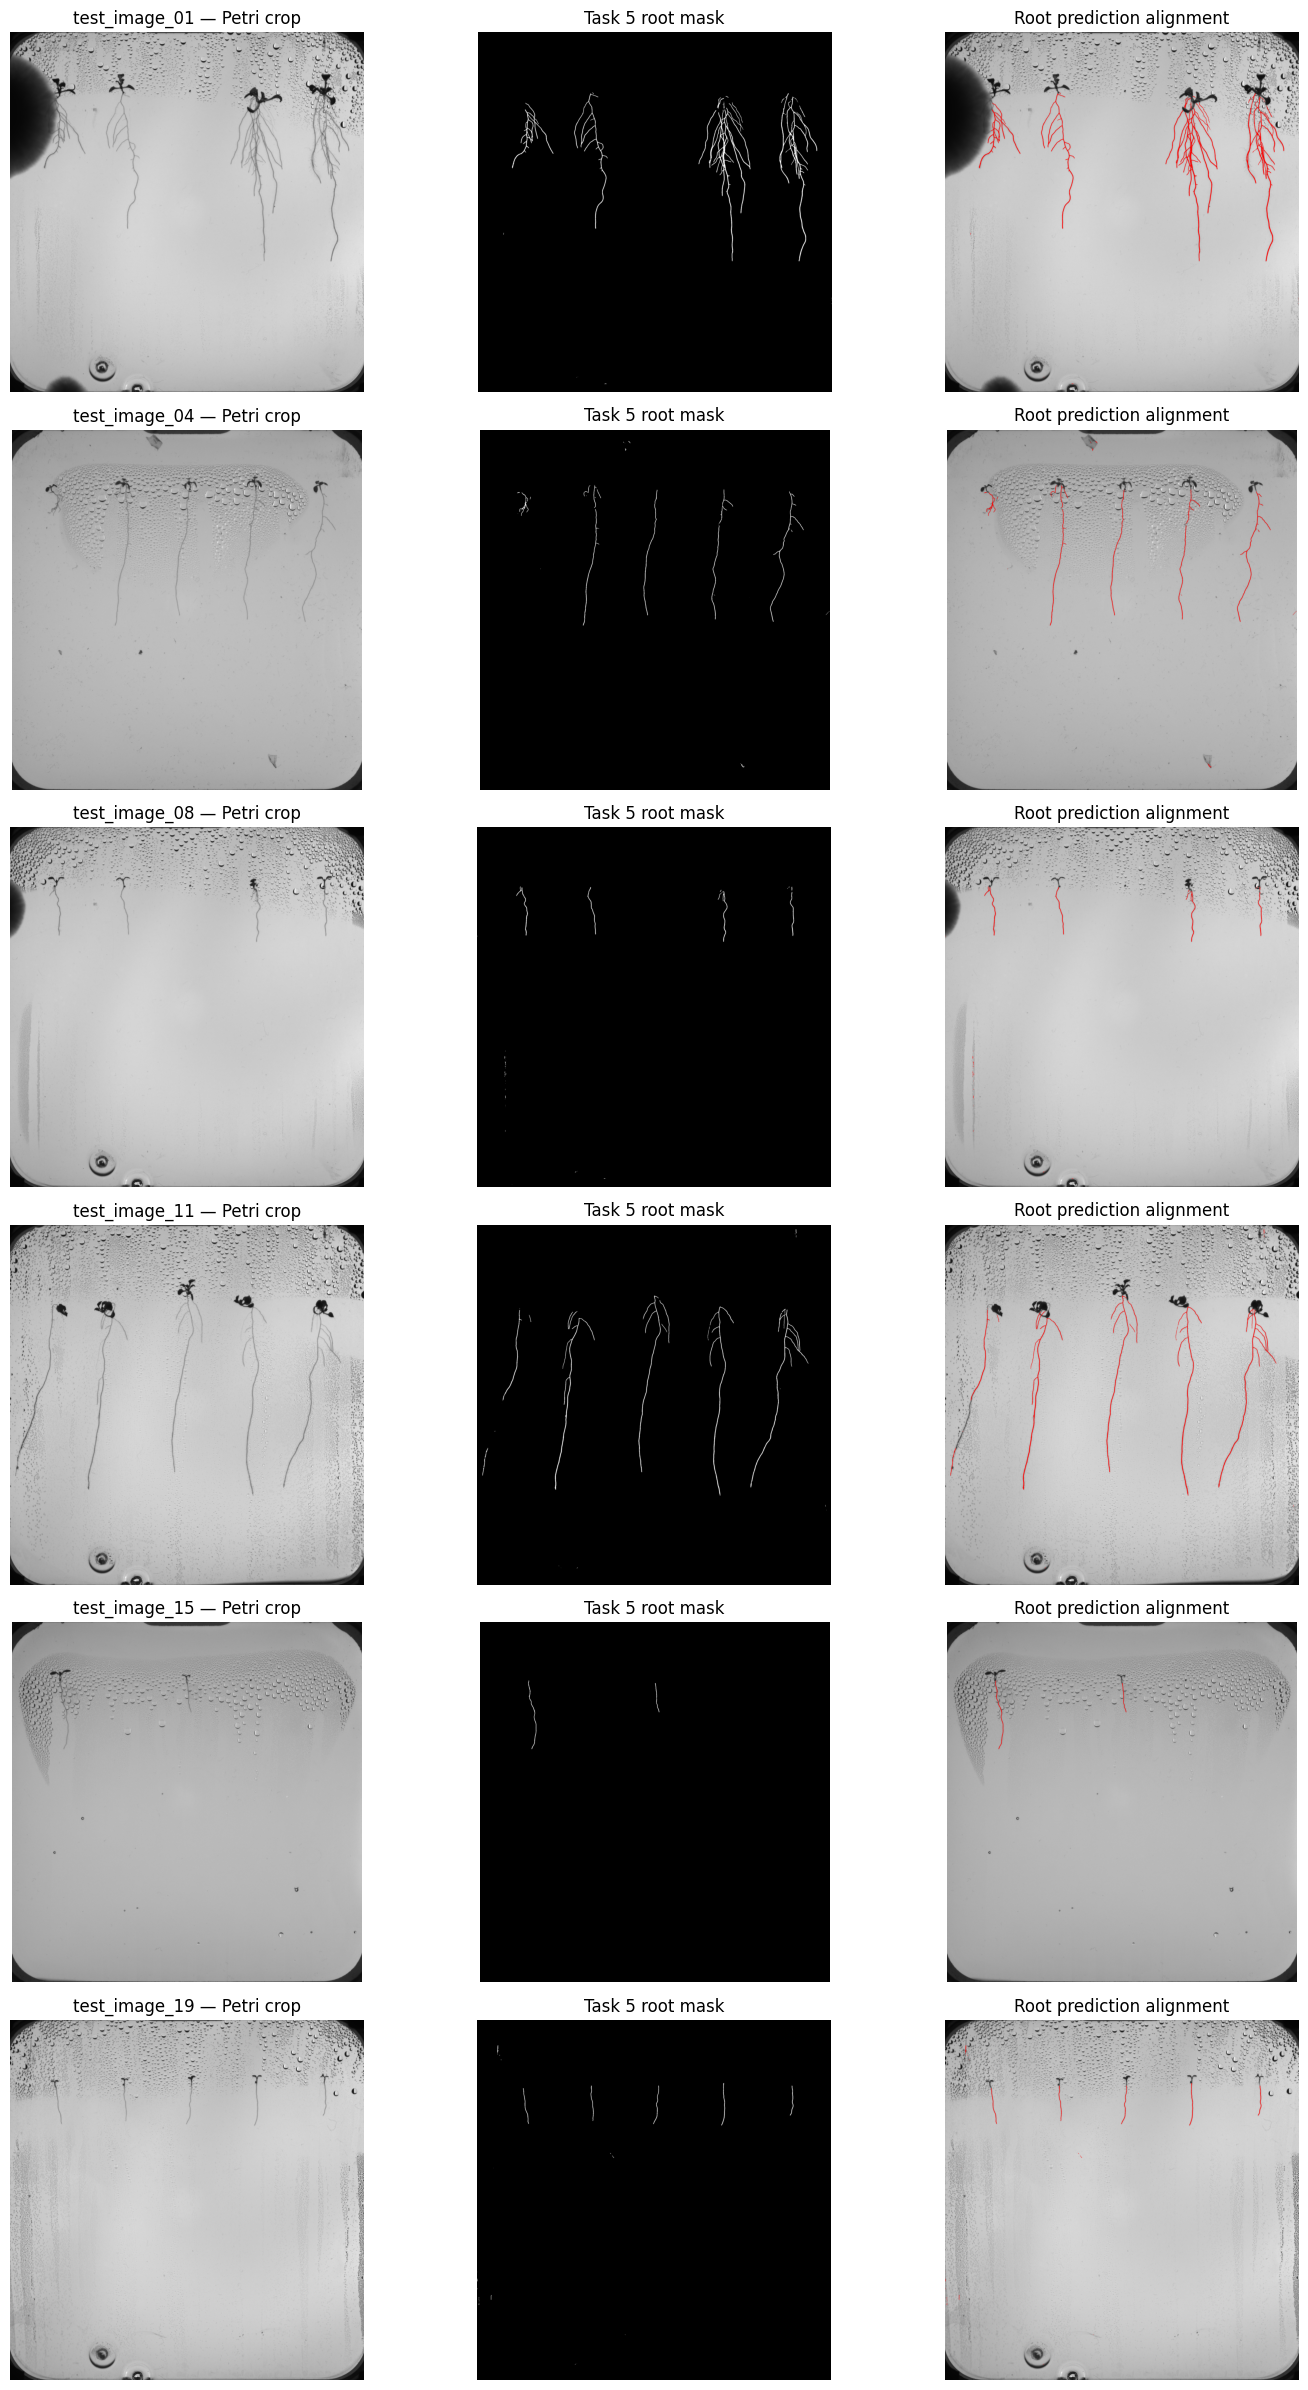

In [8]:
# ============================================================
# 4. U-Net root segmentation — SANITY CHECK
# ============================================================

check_indices = np.linspace(
    0,
    len(petri_images) - 1,
    min(6, len(petri_images))
).astype(int)

fig, axes = plt.subplots(
    len(check_indices),
    3,
    figsize=(15, 4 * len(check_indices))
)

if len(check_indices) == 1:
    axes = np.asarray([axes])

for row, idx in enumerate(check_indices):

    image_path = petri_images[idx]
    stem = image_path.stem.replace("_petri", "")

    bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(
        str(MASK_DIR / f"{stem}_root_mask.png"),
        cv2.IMREAD_GRAYSCALE
    ) > 0

    overlay = rgb.copy()
    overlay[mask] = [255, 0, 0]

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"{stem} — Petri crop")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("Task 5 root mask")

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("Root prediction alignment")

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


### CHECKPOINT 1

Inspect the U-Net root segmentation alignment above. The predicted roots should follow the visible roots well.

Only continue when this looks correct.


## Root-start localization

The root-only detector finds candidate origins. V5.1 removes bad low detections and rescues missed tiny roots. This is the working head/origin stage.


In [10]:
# ============================================================
# 5. ROOT-START DETECTION — BASE + V5.1 REFINEMENT
# ============================================================

# ============================================================
# CELL 8 — DYNAMIC ROOT-ORIGIN DETECTION
# ============================================================

import cv2
import numpy as np
import pandas as pd

from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks


def remove_tiny_components(mask, min_area=20):
    """
    Remove only extremely small isolated predictions.
    Deliberately conservative so young roots survive.
    """

    binary = (mask > 0).astype(np.uint8)

    n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        binary,
        connectivity=8
    )

    cleaned = np.zeros_like(binary)

    for label_id in range(1, n_labels):

        area = stats[
            label_id,
            cv2.CC_STAT_AREA
        ]

        if area >= min_area:
            cleaned[
                labels == label_id
            ] = 1

    return cleaned


def build_root_anchor_score(mask):
    """
    Horizontal score indicating likely plant/root-origin X positions.

    Combines:
    1. root density in the upper part of the plate
    2. how high roots first appear in each column
    """

    H, W = mask.shape

    upper_h = int(H * 0.50)

    upper = mask[
        :upper_h
    ].astype(np.uint8)

    # --------------------------------------------------------
    # Signal 1: amount of root structure in each X column
    # --------------------------------------------------------

    density = upper.sum(
        axis=0
    ).astype(np.float32)

    density = np.log1p(
        density
    )

    sigma = max(
        5,
        int(W * 0.0025)
    )

    density = gaussian_filter1d(
        density,
        sigma=sigma
    )

    # --------------------------------------------------------
    # Signal 2: roots that begin high in the image
    # --------------------------------------------------------

    top_score = np.zeros(
        W,
        dtype=np.float32
    )

    occupied_columns = np.where(
        upper.any(axis=0)
    )[0]

    for x in occupied_columns:

        first_y = int(
            np.argmax(
                upper[:, x] > 0
            )
        )

        top_score[x] = np.exp(
            -first_y / max(1.0, H * 0.15)
        )

    top_score = gaussian_filter1d(
        top_score,
        sigma=sigma
    )

    # --------------------------------------------------------
    # Normalize both signals
    # --------------------------------------------------------

    if density.max() > 0:
        density /= density.max()

    if top_score.max() > 0:
        top_score /= top_score.max()

    combined = (
        0.60 * density +
        0.40 * top_score
    )

    return combined


def find_anchor_x_positions(mask):
    """
    Find an unknown number of candidate plants.
    """

    H, W = mask.shape

    score = build_root_anchor_score(
        mask
    )

    if score.max() <= 0:
        return [], score

    min_distance = max(
        100,
        int(W * 0.075)
    )

    peaks, properties = find_peaks(
        score,
        distance=min_distance,
        height=score.max() * 0.10,
        prominence=score.max() * 0.035
    )

    peaks = sorted(
        int(x)
        for x in peaks
    )

    return peaks, score


def find_supported_start(
    mask,
    anchor_x,
    left_bound,
    right_bound
):
    """
    Find the highest root pixel near an anchor that also
    has genuine downward root support.

    This rejects many isolated false-positive specks.
    """

    H, W = mask.shape

    search_bottom = int(
        H * 0.60
    )

    support_height = max(
        70,
        int(H * 0.055)
    )

    support_radius = max(
        20,
        int(W * 0.012)
    )

    region = mask[
        :search_bottom,
        left_bound:right_bound
    ]

    for y in range(search_bottom):

        row_x = np.flatnonzero(
            region[y]
        )

        if len(row_x) == 0:
            continue

        absolute_x = (
            row_x +
            left_bound
        )

        # Try pixels nearest the anchor first
        order = np.argsort(
            np.abs(
                absolute_x -
                anchor_x
            )
        )

        # No reason to test hundreds of pixels
        for index in order[:10]:

            x = int(
                absolute_x[index]
            )

            y2 = min(
                H,
                y + support_height
            )

            x0 = max(
                left_bound,
                x - support_radius
            )

            x1 = min(
                right_bound,
                x + support_radius + 1
            )

            support = mask[
                y:y2,
                x0:x1
            ]

            total_support = int(
                support.sum()
            )

            halfway = min(
                y2,
                y + support_height // 2
            )

            lower_support = int(
                mask[
                    halfway:y2,
                    x0:x1
                ].sum()
            )

            # Must actually continue downward.
            if (
                total_support >= 25
                and
                lower_support >= 4
            ):
                return (
                    x,
                    y
                )

    return None


def detect_root_origins(mask):
    """
    Complete dynamic detector.

    Returns starts as:
        [(x, y), ...]
    ordered from left to right.
    """

    clean = remove_tiny_components(
        mask,
        min_area=20
    )

    anchors, score = find_anchor_x_positions(
        clean
    )

    if len(anchors) == 0:
        return [], clean, score

    H, W = clean.shape

    starts = []

    for i, anchor_x in enumerate(anchors):

        if i == 0:
            left = 0
        else:
            left = (
                anchors[i - 1] +
                anchor_x
            ) // 2

        if i == len(anchors) - 1:
            right = W
        else:
            right = (
                anchor_x +
                anchors[i + 1]
            ) // 2

        start = find_supported_start(
            clean,
            anchor_x,
            left,
            right
        )

        if start is not None:
            starts.append(start)

    starts = sorted(
        starts,
        key=lambda p: p[0]
    )

    return starts, clean, score

# ============================================================
# CELL 11 — V5.1-STYLE MASK-ONLY REFINEMENT
# remove low false starts + rescue tiny roots
# ============================================================

import cv2
import numpy as np
import pandas as pd


def estimate_true_plant_row(mask, starts):
    H, W = mask.shape

    # Trust starts already found in the upper half
    ys = [
        int(y)
        for x, y in starts
        if y < H * 0.45
    ]

    if len(ys) >= 2:
        return int(np.median(ys))

    # Fallback only if preliminary detector found almost nothing
    root_y, root_x = np.where(mask > 0)

    if len(root_y) == 0:
        return int(H * 0.20)

    return int(np.percentile(root_y, 5))


def component_start_candidate(
    labels,
    component_id,
    stats,
    y_offset,
    plant_y
):
    x = int(stats[component_id, cv2.CC_STAT_LEFT])
    y = int(stats[component_id, cv2.CC_STAT_TOP])
    w = int(stats[component_id, cv2.CC_STAT_WIDTH])
    h = int(stats[component_id, cv2.CC_STAT_HEIGHT])
    area = int(stats[component_id, cv2.CC_STAT_AREA])

    ys, xs = np.where(
        labels == component_id
    )

    if len(ys) == 0:
        return None

    absolute_ys = ys + y_offset

    top_y = int(absolute_ys.min())
    bottom_y = int(absolute_ys.max())

    vertical_span = bottom_y - top_y

    # Tiny noise
    if area < 8:
        return None

    if vertical_span < 12:
        return None

    # Candidate must begin near the biological plant row
    row_tolerance = max(
        75,
        int(labels.shape[0] * 0.08)
    )

    if top_y > plant_y + row_tolerance:
        return None

    # Must genuinely continue downward
    if bottom_y < plant_y + 8:
        return None

    # Very tiny candidates should actually look root-like,
    # not like a wide condensation blob.
    verticality = vertical_span / max(w, 1)

    if vertical_span < 35 and verticality < 0.65:
        return None

    # Find the component's highest few root pixels.
    local_top = ys.min()

    top_pixels = np.where(
        (labels == component_id)
        &
        (
            np.indices(labels.shape)[0]
            <= local_top + 6
        )
    )

    if len(top_pixels[0]) == 0:
        return None

    candidate_x = int(
        np.median(top_pixels[1])
    )

    candidate_y = int(
        top_pixels[0].min() + y_offset
    )

    score = (
        vertical_span
        + 0.04 * area
        + 5.0 * verticality
    )

    return {
        "x": candidate_x,
        "y": candidate_y,
        "score": float(score),
        "height": h,
        "width": w,
        "area": area
    }


def refine_root_starts_v51(mask, preliminary_starts):
    """
    Keep trustworthy root-only starts.
    Remove low false detections.
    Rescue tiny root systems near the plant row.
    """

    mask = (mask > 0).astype(np.uint8)

    H, W = mask.shape

    plant_y = estimate_true_plant_row(
        mask,
        preliminary_starts
    )

    # --------------------------------------------------------
    # 1. Remove obvious LOW false detections
    # --------------------------------------------------------

    y_tolerance = max(
        90,
        int(H * 0.055)
    )

    accepted = [
        {
            "x": int(x),
            "y": int(y),
            "score": 1e9,
            "source": "original"
        }
        for x, y in preliminary_starts
        if abs(y - plant_y) <= y_tolerance
    ]

    # --------------------------------------------------------
    # 2. Search only around the biological root-start region
    # --------------------------------------------------------

    band_up = max(
        55,
        int(H * 0.035)
    )

    band_down = max(
        220,
        int(H * 0.12)
    )

    y0 = max(
        0,
        plant_y - band_up
    )

    y1 = min(
        H,
        plant_y + band_down
    )

    band = mask[
        y0:y1
    ]

    n_labels, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            band,
            connectivity=8
        )
    )

    rescue_candidates = []

    border = int(W * 0.02)

    for component_id in range(
        1,
        n_labels
    ):

        candidate = component_start_candidate(
            labels,
            component_id,
            stats,
            y0,
            plant_y
        )

        if candidate is None:
            continue

        x = candidate["x"]

        if x < border or x >= W - border:
            continue

        # If an original start already represents this plant,
        # this component is not a rescue.
        nearest_original = min(
            (
                abs(x - item["x"])
                for item in accepted
            ),
            default=np.inf
        )

        existing_radius = max(
            100,
            int(W * 0.035)
        )

        if nearest_original <= existing_radius:
            continue

        candidate["source"] = "rescue"

        rescue_candidates.append(
            candidate
        )

    # --------------------------------------------------------
    # 3. Combine originals + rescue candidates
    # --------------------------------------------------------

    all_candidates = (
        accepted
        +
        rescue_candidates
    )

    if len(all_candidates) == 0:
        return [], plant_y, []

    all_candidates = sorted(
        all_candidates,
        key=lambda item: item["x"]
    )

    # --------------------------------------------------------
    # 4. Merge candidates that clearly describe same plant
    # --------------------------------------------------------

    merge_distance = max(
        80,
        int(W * 0.028)
    )

    groups = []

    for candidate in all_candidates:

        if not groups:
            groups.append(
                [candidate]
            )
            continue

        if (
            candidate["x"]
            -
            groups[-1][-1]["x"]
            <= merge_distance
        ):
            groups[-1].append(
                candidate
            )

        else:
            groups.append(
                [candidate]
            )

    final = []

    for group in groups:

        # Original detector wins if present.
        originals = [
            g
            for g in group
            if g["source"] == "original"
        ]

        if originals:
            best = originals[0]

        else:
            best = max(
                group,
                key=lambda g: g["score"]
            )

        final.append(
            (
                int(best["x"]),
                int(best["y"])
            )
        )

    final = sorted(
        final,
        key=lambda p: p[0]
    )

    return (
        final,
        plant_y,
        rescue_candidates
    )

In [11]:
# ============================================================
# 6. RUN ROOT-START DETECTION + V5.1 REFINEMENT
# ============================================================

# ============================================================
# CELL 9 — RUN ROOT-ORIGIN DETECTION ON ALL IMAGES
# ============================================================

ROOT_START_DIR = (
    OUTPUT_DIR /
    "04_root_starts"
)

ROOT_START_DIR.mkdir(
    parents=True,
    exist_ok=True
)

root_start_records = []
detected_starts = {}


for image_path in petri_images:

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    mask_path = (
        MASK_DIR /
        f"{stem}_root_mask.png"
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    assert mask is not None, (
        f"Missing root mask: {mask_path}"
    )

    mask = (
        mask > 0
    ).astype(np.uint8)

    starts, clean_mask, score = detect_root_origins(
        mask
    )

    detected_starts[stem] = starts

    print(
        f"{stem}: {len(starts)} starts"
    )

    for plant_index, (x, y) in enumerate(
        starts,
        start=1
    ):

        root_start_records.append({
            "image": stem,
            "plant": plant_index,
            "x": int(x),
            "y": int(y)
        })


root_starts_df = pd.DataFrame(
    root_start_records
)

root_starts_df.to_csv(
    ROOT_START_DIR /
    "detected_root_starts.csv",
    index=False
)

print()
print(
    "Total starts:",
    len(root_starts_df)
)

display(root_starts_df)

# ============================================================
# CELL 12 — RUN V5.1 REFINEMENT
# ============================================================

V51_DIR = OUTPUT_DIR / "05_v51_starts"
V51_DIR.mkdir(
    parents=True,
    exist_ok=True
)

v51_results = {}
v51_records = []

for image_path in petri_images:

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    mask_path = (
        MASK_DIR /
        f"{stem}_root_mask.png"
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    assert mask is not None, (
        f"Missing mask: {mask_path}"
    )

    mask = (
        mask > 0
    ).astype(np.uint8)

    preliminary = detected_starts[
        stem
    ]

    starts, plant_y, rescues = refine_root_starts_v51(
        mask,
        preliminary
    )

    v51_results[stem] = {
        "starts": starts,
        "plant_y": plant_y,
        "rescues": rescues
    }

    print(
        f"{stem}: "
        f"{len(preliminary)} -> {len(starts)} "
        f"(rescued {len(rescues)})"
    )

    for plant_id, (x, y) in enumerate(
        starts,
        start=1
    ):
        v51_records.append({
            "image": stem,
            "plant": plant_id,
            "x": x,
            "y": y
        })


v51_df = pd.DataFrame(
    v51_records
)

v51_df.to_csv(
    V51_DIR / "v51_root_starts.csv",
    index=False
)

print()
print(
    "Final total starts:",
    len(v51_df)
)

test_image_01: 4 starts
test_image_02: 6 starts
test_image_03: 3 starts
test_image_04: 5 starts
test_image_05: 2 starts
test_image_06: 4 starts
test_image_07: 5 starts
test_image_08: 4 starts
test_image_09: 5 starts
test_image_10: 5 starts
test_image_11: 5 starts
test_image_12: 5 starts
test_image_13: 5 starts
test_image_14: 5 starts
test_image_15: 2 starts
test_image_16: 5 starts
test_image_17: 6 starts
test_image_18: 5 starts
test_image_19: 5 starts

Total starts: 86


,image,plant,x,y
0,test_image_01,1,364,551
1,test_image_01,2,881,472
2,test_image_01,3,1906,500
3,test_image_01,4,2387,478
4,test_image_02,1,189,44
...,...,...,...,...
81,test_image_19,1,357,532
82,test_image_19,2,881,512
83,test_image_19,3,1395,512
84,test_image_19,4,1899,492


test_image_01: 4 -> 4 (rescued 0)
test_image_02: 6 -> 5 (rescued 2)
test_image_03: 3 -> 3 (rescued 1)
test_image_04: 5 -> 5 (rescued 0)
test_image_05: 2 -> 4 (rescued 2)
test_image_06: 4 -> 5 (rescued 1)
test_image_07: 5 -> 5 (rescued 0)
test_image_08: 4 -> 4 (rescued 0)
test_image_09: 5 -> 5 (rescued 1)
test_image_10: 5 -> 5 (rescued 0)
test_image_11: 5 -> 5 (rescued 0)
test_image_12: 5 -> 5 (rescued 0)
test_image_13: 5 -> 5 (rescued 0)
test_image_14: 5 -> 5 (rescued 0)
test_image_15: 2 -> 2 (rescued 0)
test_image_16: 5 -> 5 (rescued 0)
test_image_17: 6 -> 5 (rescued 1)
test_image_18: 5 -> 5 (rescued 0)
test_image_19: 5 -> 5 (rescued 0)

Final total starts: 87


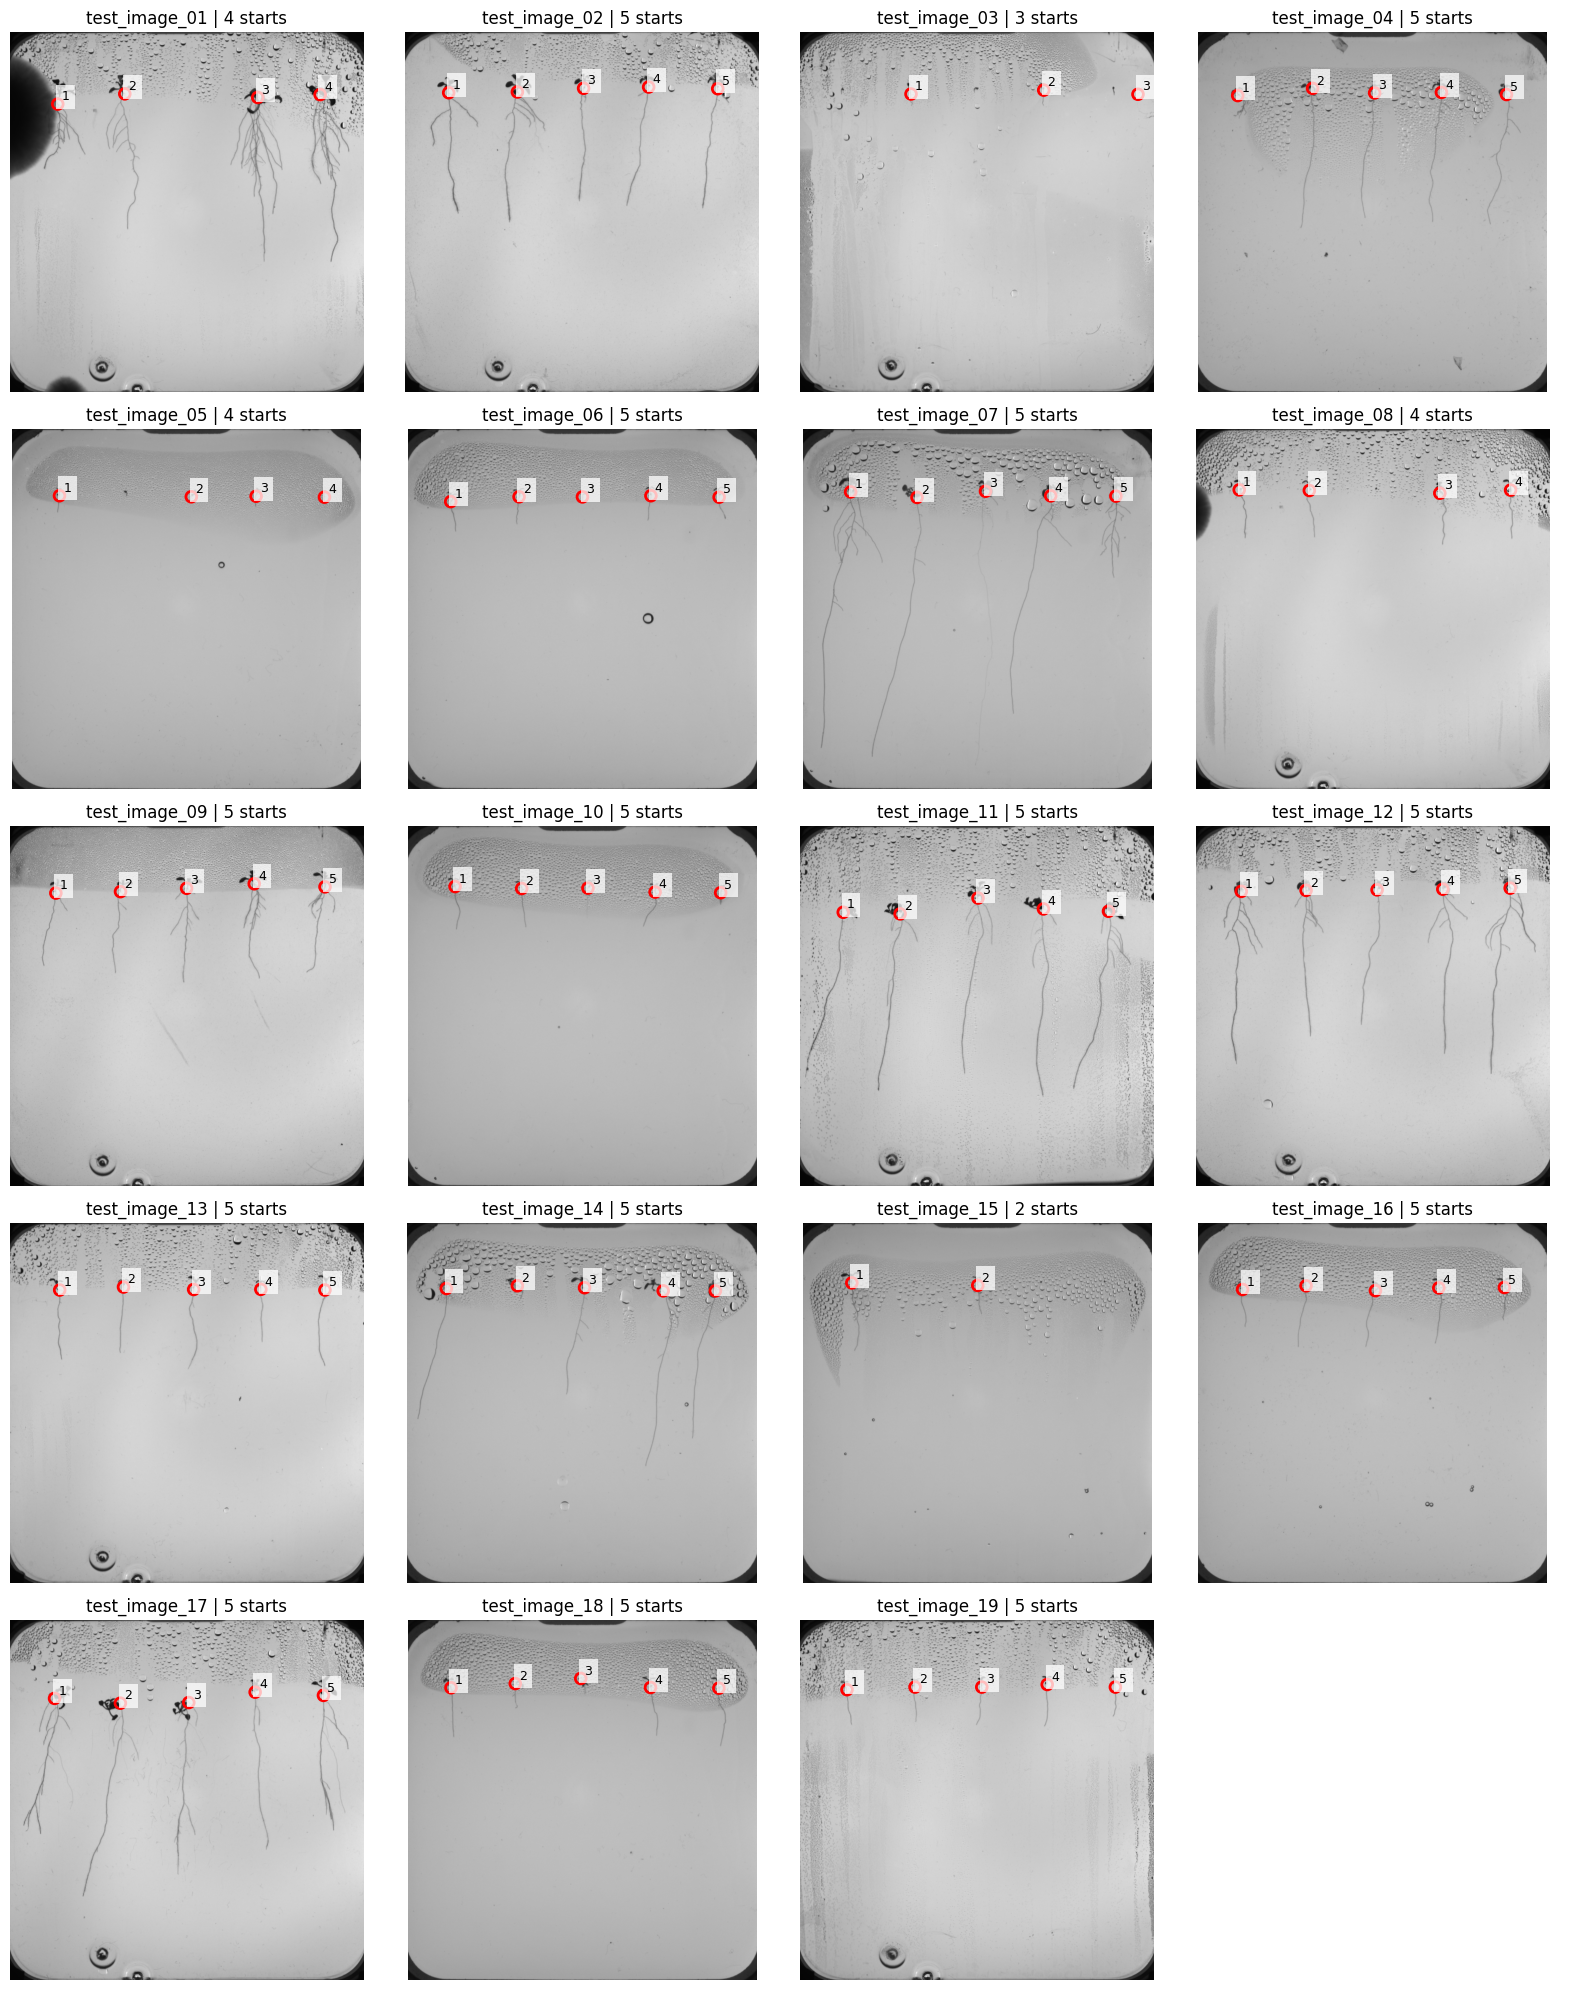

In [12]:
# ============================================================
# 7. V5.1 ROOT-START SANITY CHECK
# ============================================================

import matplotlib.pyplot as plt

cols = 4
rows = int(
    np.ceil(
        len(petri_images) / cols
    )
)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, 4 * rows)
)

axes = np.asarray(
    axes
).ravel()


for ax, image_path in zip(
    axes,
    petri_images
):

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    bgr = cv2.imread(
        str(image_path)
    )

    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    result = v51_results[
        stem
    ]

    starts = result[
        "starts"
    ]

    H, W = rgb.shape[:2]

    scale = min(
        1.0,
        650 / W
    )

    small = cv2.resize(
        rgb,
        (
            int(W * scale),
            int(H * scale)
        ),
        interpolation=cv2.INTER_AREA
    )

    ax.imshow(
        small
    )

    for plant_id, (x, y) in enumerate(
        starts,
        start=1
    ):

        ax.scatter(
            x * scale,
            y * scale,
            s=60,
            facecolors="none",
            edgecolors="red",
            linewidths=2
        )

        ax.text(
            x * scale + 7,
            y * scale - 7,
            str(plant_id),
            fontsize=9,
            bbox=dict(
                facecolor="white",
                alpha=0.75,
                edgecolor="none"
            )
        )

    ax.set_title(
        f"{stem} | {len(starts)} starts"
    )

    ax.axis("off")


for ax in axes[
    len(petri_images):
]:
    ax.axis("off")


plt.tight_layout()
plt.show()

### CHECKPOINT 2

Every biological plant should have one correctly placed root-start marker. Once correct, this stage is frozen.


## Individual root segmentation — Individual root assignment

Root pixels are assigned to the secured biological starts. Touching root systems are split geodesically and disconnected fragments are assigned using root proximity and horizontal alignment.


In [13]:
# ============================================================
# 8. Individual root segmentation — INDIVIDUAL ROOT ASSIGNMENT
# ============================================================
#
# Goal:
# Assign every predicted root component to the correct plant.
#
# Strategy:
# 1. Starts from V5.1 are treated as trusted biological origins.
# 2. Components containing a start are assigned immediately.
# 3. Components containing several starts are split geodesically.
# 4. Disconnected root fragments are attached to the most
#    plausible plant using root-to-root proximity and X alignment.
# 5. Tiny unrelated predictions may remain unassigned as noise.
#
# IMPORTANT:
# No artificial bridge pixels are added to the final root masks.
# ============================================================

import cv2
import heapq
import numpy as np

from scipy.spatial import cKDTree


NEIGHBORS_8 = [
    (-1, -1, np.sqrt(2)),
    (-1,  0, 1.0),
    (-1,  1, np.sqrt(2)),
    ( 0, -1, 1.0),
    ( 0,  1, 1.0),
    ( 1, -1, np.sqrt(2)),
    ( 1,  0, 1.0),
    ( 1,  1, np.sqrt(2)),
]


def snap_start_to_root(mask, x, y, radius=40):
    """
    Snap a V5.1 start onto the nearest real predicted root pixel.
    """

    H, W = mask.shape

    x = int(x)
    y = int(y)

    if (
        0 <= x < W
        and 0 <= y < H
        and mask[y, x]
    ):
        return x, y

    x0 = max(0, x - radius)
    x1 = min(W, x + radius + 1)

    y0 = max(0, y - radius)
    y1 = min(H, y + radius + 1)

    ys, xs = np.where(
        mask[y0:y1, x0:x1] > 0
    )

    if len(ys) == 0:
        return None

    xs = xs + x0
    ys = ys + y0

    d2 = (
        (xs - x) ** 2
        +
        (ys - y) ** 2
    )

    best = int(
        np.argmin(d2)
    )

    return (
        int(xs[best]),
        int(ys[best])
    )


def get_component_info(
    labels,
    stats,
    component_id
):
    """
    Extract useful geometry for one original root component.
    """

    x0 = int(
        stats[
            component_id,
            cv2.CC_STAT_LEFT
        ]
    )

    y0 = int(
        stats[
            component_id,
            cv2.CC_STAT_TOP
        ]
    )

    w = int(
        stats[
            component_id,
            cv2.CC_STAT_WIDTH
        ]
    )

    h = int(
        stats[
            component_id,
            cv2.CC_STAT_HEIGHT
        ]
    )

    area = int(
        stats[
            component_id,
            cv2.CC_STAT_AREA
        ]
    )

    local = (
        labels[
            y0:y0 + h,
            x0:x0 + w
        ]
        ==
        component_id
    )

    ly, lx = np.where(local)

    gy = ly + y0
    gx = lx + x0

    top_y = int(
        gy.min()
    )

    bottom_y = int(
        gy.max()
    )

    top_band = (
        gy <= top_y + 12
    )

    top_x = int(
        np.median(
            gx[top_band]
        )
    )

    top_points = np.column_stack(
        (
            gy[top_band],
            gx[top_band]
        )
    )

    all_points = np.column_stack(
        (
            gy,
            gx
        )
    )

    return {
        "id": component_id,
        "area": area,
        "x0": x0,
        "y0": y0,
        "width": w,
        "height": h,
        "top_y": top_y,
        "bottom_y": bottom_y,
        "vertical_span": bottom_y - top_y,
        "top_x": top_x,
        "top_points": top_points,
        "points": all_points
    }


def split_multi_start_component(
    labels,
    stats,
    component_id,
    seeds,
    final_owner
):
    """
    If roots from multiple plants actually touch in the
    segmentation, split only that connected structure using
    geodesic distance along genuine root pixels.
    """

    x0 = int(
        stats[
            component_id,
            cv2.CC_STAT_LEFT
        ]
    )

    y0 = int(
        stats[
            component_id,
            cv2.CC_STAT_TOP
        ]
    )

    w = int(
        stats[
            component_id,
            cv2.CC_STAT_WIDTH
        ]
    )

    h = int(
        stats[
            component_id,
            cv2.CC_STAT_HEIGHT
        ]
    )

    component = (
        labels[
            y0:y0 + h,
            x0:x0 + w
        ]
        ==
        component_id
    )

    distance = np.full(
        component.shape,
        np.inf,
        dtype=np.float32
    )

    owner = np.zeros(
        component.shape,
        dtype=np.int32
    )

    queue = []

    for plant_id, sx, sy in seeds:

        lx = sx - x0
        ly = sy - y0

        distance[
            ly,
            lx
        ] = 0.0

        owner[
            ly,
            lx
        ] = plant_id

        heapq.heappush(
            queue,
            (
                0.0,
                ly,
                lx,
                plant_id
            )
        )

    while queue:

        dist, y, x, plant_id = heapq.heappop(
            queue
        )

        if dist > distance[y, x]:
            continue

        for dy, dx, step in NEIGHBORS_8:

            ny = y + dy
            nx = x + dx

            if not (
                0 <= ny < h
                and
                0 <= nx < w
            ):
                continue

            if not component[ny, nx]:
                continue

            new_dist = dist + step

            if new_dist < distance[ny, nx]:

                distance[
                    ny,
                    nx
                ] = new_dist

                owner[
                    ny,
                    nx
                ] = plant_id

                heapq.heappush(
                    queue,
                    (
                        new_dist,
                        ny,
                        nx,
                        plant_id
                    )
                )

    roi = final_owner[
        y0:y0 + h,
        x0:x0 + w
    ]

    roi[
        component
    ] = owner[
        component
    ]


def build_plant_trees(
    owner_map,
    plant_ids,
    max_points=25000
):
    """
    KD-trees provide fast distance from a disconnected
    root component to roots already owned by each plant.
    """

    trees = {}

    for plant_id in plant_ids:

        coords = np.argwhere(
            owner_map == plant_id
        )

        if len(coords) == 0:
            trees[
                plant_id
            ] = None

            continue

        if len(coords) > max_points:

            step = int(
                np.ceil(
                    len(coords)
                    /
                    max_points
                )
            )

            coords = coords[
                ::step
            ]

        trees[
            plant_id
        ] = cKDTree(
            coords
        )

    return trees


def assign_roots_to_plants(
    mask,
    starts
):
    """
    Robust individual-root assignment.

    Works on the ORIGINAL Task 5 mask.
    """

    mask = (
        mask > 0
    ).astype(np.uint8)

    H, W = mask.shape

    final_owner = np.zeros(
        (H, W),
        dtype=np.int32
    )

    # --------------------------------------------------------
    # Snap trusted V5.1 origins to real mask pixels
    # --------------------------------------------------------

    snapped_starts = []

    for plant_id, (x, y) in enumerate(
        starts,
        start=1
    ):

        snapped = snap_start_to_root(
            mask,
            x,
            y
        )

        if snapped is None:
            raise RuntimeError(
                f"Plant {plant_id}: "
                f"no root pixel near start ({x}, {y})"
            )

        sx, sy = snapped

        snapped_starts.append(
            (
                plant_id,
                sx,
                sy
            )
        )

    plant_ids = [
        p[0]
        for p in snapped_starts
    ]

    start_lookup = {
        plant_id: (
            x,
            y
        )
        for plant_id, x, y
        in snapped_starts
    }

    # --------------------------------------------------------
    # Original U-Net root segmentation connected components
    # --------------------------------------------------------

    n_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            mask,
            connectivity=8
        )
    )

    components = {}

    for component_id in range(
        1,
        n_labels
    ):

        components[
            component_id
        ] = get_component_info(
            labels,
            stats,
            component_id
        )

    # --------------------------------------------------------
    # Which components contain biological starts?
    # --------------------------------------------------------

    component_seeds = {}

    for plant_id, x, y in snapped_starts:

        component_id = int(
            labels[
                y,
                x
            ]
        )

        component_seeds.setdefault(
            component_id,
            []
        ).append(
            (
                plant_id,
                x,
                y
            )
        )

    assigned_components = set()

    # --------------------------------------------------------
    # Seeded components
    # --------------------------------------------------------

    for component_id, seeds in component_seeds.items():

        if component_id == 0:
            continue

        component = (
            labels == component_id
        )

        if len(seeds) == 1:

            plant_id = seeds[
                0
            ][0]

            final_owner[
                component
            ] = plant_id

        else:

            split_multi_start_component(
                labels,
                stats,
                component_id,
                seeds,
                final_owner
            )

        assigned_components.add(
            component_id
        )

    # --------------------------------------------------------
    # Root spacing gives us a biological scale.
    # --------------------------------------------------------

    start_xs = sorted(
        x
        for _, x, _
        in snapped_starts
    )

    if len(start_xs) >= 2:

        median_spacing = float(
            np.median(
                np.diff(
                    start_xs
                )
            )
        )

    else:

        median_spacing = (
            W * 0.5
        )

    # --------------------------------------------------------
    # Unseeded components
    # --------------------------------------------------------

    remaining = {
        cid
        for cid in components
        if cid not in assigned_components
    }

    # Attach from top downward.
    # Several passes allow chains of disconnected fragments.
    for _ in range(4):

        if not remaining:
            break

        trees = build_plant_trees(
            final_owner,
            plant_ids
        )

        newly_assigned = []

        ordered_components = sorted(
            remaining,
            key=lambda cid:
                components[
                    cid
                ]["top_y"]
        )

        for component_id in ordered_components:

            info = components[
                component_id
            ]

            # Ignore obvious microscopic noise.
            if (
                info["area"] < 8
                or
                info["vertical_span"] < 5
            ):
                continue

            best_plant = None
            best_score = np.inf
            best_root_distance = np.inf

            for plant_id in plant_ids:

                tree = trees[
                    plant_id
                ]

                if tree is None:
                    continue

                sx, sy = start_lookup[
                    plant_id
                ]

                # Component should not begin far above its plant.
                if (
                    info["top_y"]
                    <
                    sy - 80
                ):
                    continue

                distances, _ = tree.query(
                    info[
                        "top_points"
                    ],
                    k=1
                )

                nearest_root_distance = float(
                    np.min(
                        distances
                    )
                )

                horizontal_offset = abs(
                    info["top_x"]
                    -
                    sx
                )

                # Root-to-root distance matters most.
                # X position only breaks ambiguity.
                score = (
                    nearest_root_distance
                    +
                    0.18
                    *
                    horizontal_offset
                )

                if score < best_score:

                    best_score = score
                    best_plant = plant_id

                    best_root_distance = (
                        nearest_root_distance
                    )

            if best_plant is None:
                continue

            max_gap = max(
                130,
                int(H * 0.065)
            )

            sx, sy = start_lookup[
                best_plant
            ]

            horizontal_offset = abs(
                info["top_x"]
                -
                sx
            )

            strong_x_alignment = (
                horizontal_offset
                <=
                median_spacing * 0.32
            )

            root_like = (
                info["vertical_span"]
                >= 12
            )

            if (
                best_root_distance
                <= max_gap
                or
                (
                    strong_x_alignment
                    and
                    root_like
                )
            ):

                final_owner[
                    labels
                    ==
                    component_id
                ] = best_plant

                newly_assigned.append(
                    component_id
                )

        for cid in newly_assigned:

            remaining.discard(
                cid
            )

        if len(newly_assigned) == 0:
            break

    # --------------------------------------------------------
    # Conservative final rescue
    #
    # Remaining root-like fragments can still be separated
    # by a larger segmentation gap. Assign only when their X
    # position strongly agrees with a plant.
    # --------------------------------------------------------

    for component_id in list(
        remaining
    ):

        info = components[
            component_id
        ]

        if (
            info["area"] < 10
            or
            info["vertical_span"] < 10
        ):
            continue

        candidate_plants = []

        for plant_id in plant_ids:

            sx, sy = start_lookup[
                plant_id
            ]

            if (
                info["top_y"]
                <
                sy - 80
            ):
                continue

            x_distance = abs(
                info["top_x"]
                -
                sx
            )

            candidate_plants.append(
                (
                    x_distance,
                    plant_id
                )
            )

        if not candidate_plants:
            continue

        x_distance, plant_id = min(
            candidate_plants
        )

        if (
            x_distance
            <=
            median_spacing * 0.45
        ):

            final_owner[
                labels
                ==
                component_id
            ] = plant_id

    return (
        final_owner,
        snapped_starts
    )

In [14]:
# ============================================================
# 9. Individual root segmentation — RUN INDIVIDUAL ROOT ASSIGNMENT
# ============================================================

from pathlib import Path
import pandas as pd


INDIVIDUAL_ROOT_DIR = (
    OUTPUT_DIR /
    "06_individual_roots"
)

INDIVIDUAL_ROOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

task6_results = {}
task6_records = []


for image_path in petri_images:

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    mask_path = (
        MASK_DIR /
        f"{stem}_root_mask.png"
    )

    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    assert mask is not None, (
        f"Missing root mask: {mask_path}"
    )

    mask = (
        mask > 0
    ).astype(np.uint8)

    starts = v51_results[
        stem
    ]["starts"]

    owner_map, snapped_starts = (
        assign_roots_to_plants(
            mask,
            starts
        )
    )

    image_dir = (
        INDIVIDUAL_ROOT_DIR /
        stem
    )

    image_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    individual_masks = {}

    for plant_id, x, y in snapped_starts:

        plant_mask = (
            owner_map
            ==
            plant_id
        ).astype(np.uint8)

        pixel_count = int(
            plant_mask.sum()
        )

        individual_masks[
            plant_id
        ] = plant_mask

        save_path = (
            image_dir /
            f"plant_{plant_id:02d}.png"
        )

        ok = cv2.imwrite(
            str(save_path),
            plant_mask * 255
        )

        assert ok, (
            f"Could not save {save_path}"
        )

        task6_records.append({
            "image": stem,
            "plant": plant_id,
            "start_x": x,
            "start_y": y,
            "root_pixels": pixel_count
        })

    # Save the complete ownership map as well.
    np.save(
        image_dir /
        "owner_map.npy",
        owner_map.astype(np.uint8)
    )

    task6_results[
        stem
    ] = {
        "owner_map": owner_map,
        "starts": snapped_starts,
        "individual_masks": individual_masks
    }

    counts = [
        int(
            individual_masks[p].sum()
        )
        for p in individual_masks
    ]

    print(
        f"{stem}: "
        f"{len(individual_masks)} plants | "
        f"pixels={counts}"
    )


task6_df = pd.DataFrame(
    task6_records
)

task6_df.to_csv(
    INDIVIDUAL_ROOT_DIR /
    "task6_root_assignment.csv",
    index=False
)

print()
print(
    "Task 6 complete:",
    len(task6_df),
    "individual root systems"
)

test_image_01: 4 plants | pixels=[9388, 11622, 34817, 25975]
test_image_02: 5 plants | pixels=[10008, 12020, 5559, 5485, 6320]
test_image_03: 3 plants | pixels=[422, 623, 126]
test_image_04: 5 plants | pixels=[1671, 5628, 4238, 5012, 5869]
test_image_05: 4 plants | pixels=[574, 132, 362, 56]
test_image_06: 5 plants | pixels=[1106, 986, 208, 841, 749]
test_image_07: 5 plants | pixels=[19084, 10069, 6293, 9779, 8413]
test_image_08: 4 plants | pixels=[2748, 1844, 2601, 1924]
test_image_09: 5 plants | pixels=[3657, 3956, 7352, 9471, 7611]
test_image_10: 5 plants | pixels=[1546, 1296, 590, 1263, 443]
test_image_11: 5 plants | pixels=[3882, 11985, 10155, 10788, 12907]
test_image_12: 5 plants | pixels=[15216, 10754, 5691, 11182, 17352]
test_image_13: 5 plants | pixels=[3314, 2577, 3406, 1923, 3339]
test_image_14: 5 plants | pixels=[5019, 634, 4644, 7924, 5941]
test_image_15: 2 plants | pixels=[2266, 919]
test_image_16: 5 plants | pixels=[1281, 2103, 2054, 2064, 1315]
test_image_17: 5 plants |

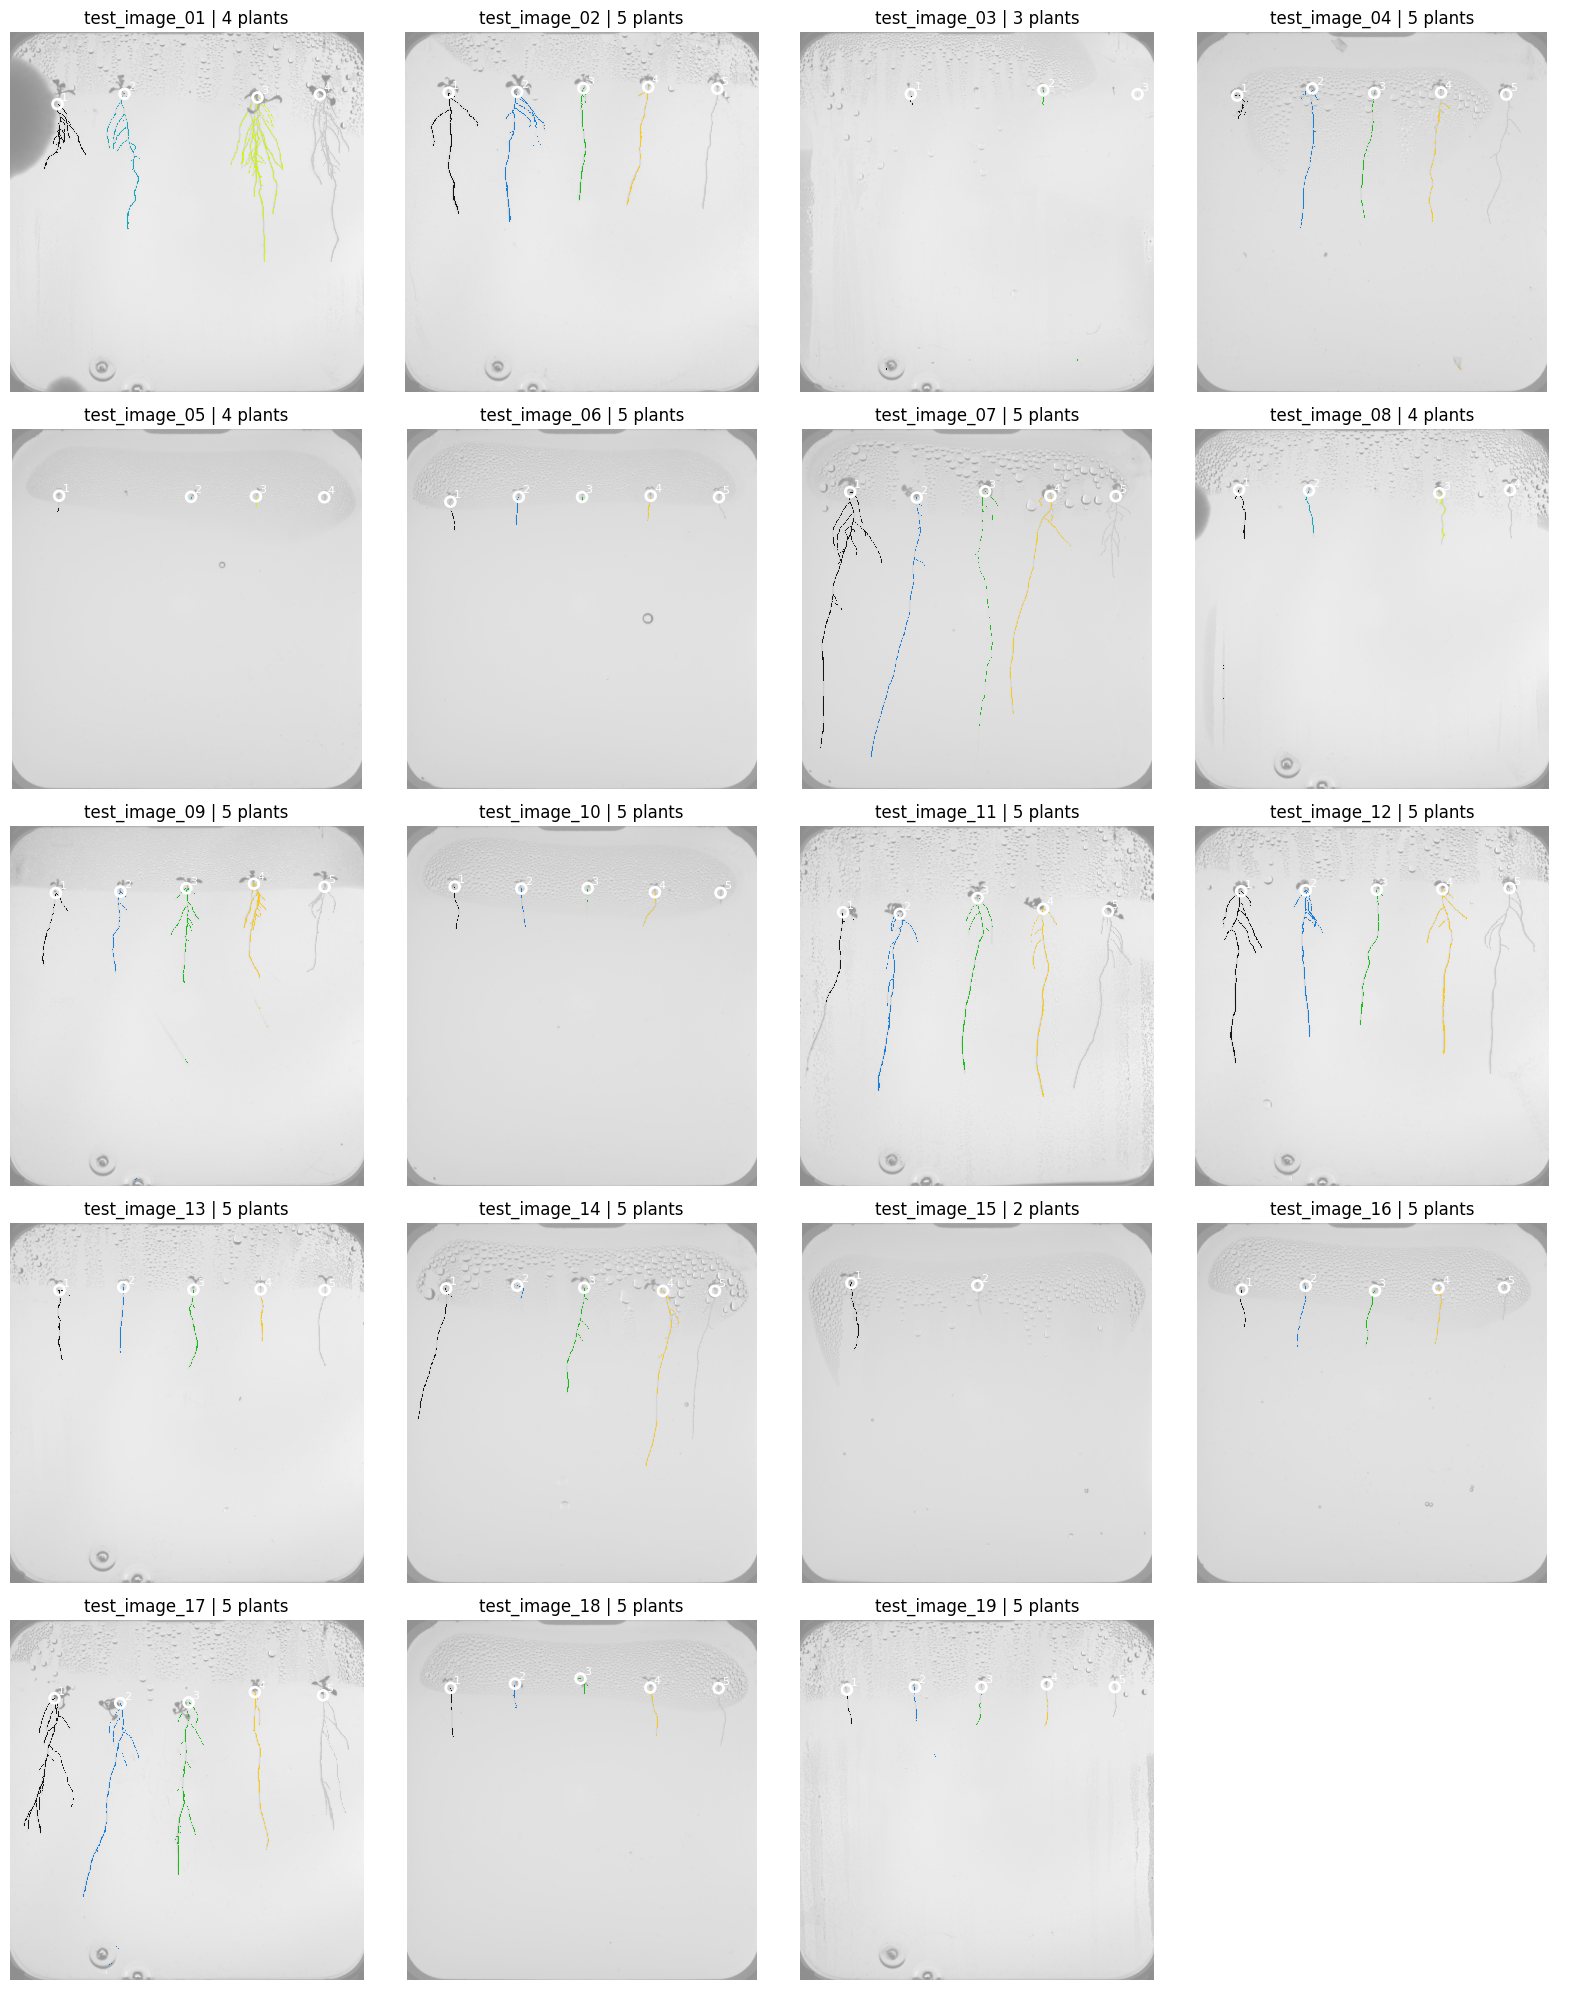

In [15]:
# ============================================================
# 10. Individual root segmentation — FINAL VISUAL QUALITY CHECK
# ============================================================

import matplotlib.pyplot as plt


cols = 4

rows = int(
    np.ceil(
        len(petri_images)
        /
        cols
    )
)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, 4 * rows)
)

axes = np.asarray(
    axes
).ravel()


for ax, image_path in zip(
    axes,
    petri_images
):

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    bgr = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    result = task6_results[
        stem
    ]

    owner = result[
        "owner_map"
    ]

    starts = result[
        "starts"
    ]

    H, W = rgb.shape[:2]

    display_width = 600

    scale = min(
        1.0,
        display_width / W
    )

    display_size = (
        int(W * scale),
        int(H * scale)
    )

    rgb_small = cv2.resize(
        rgb,
        display_size,
        interpolation=cv2.INTER_AREA
    )

    owner_small = cv2.resize(
        owner.astype(np.uint8),
        display_size,
        interpolation=cv2.INTER_NEAREST
    )

    ax.imshow(
        rgb_small,
        alpha=0.45
    )

    masked_owner = np.ma.masked_where(
        owner_small == 0,
        owner_small
    )

    ax.imshow(
        masked_owner,
        cmap="nipy_spectral",
        interpolation="nearest",
        alpha=0.9
    )

    for plant_id, x, y in starts:

        ax.scatter(
            x * scale,
            y * scale,
            s=50,
            facecolors="none",
            edgecolors="white",
            linewidths=2
        )

        ax.text(
            x * scale + 6,
            y * scale - 6,
            str(plant_id),
            fontsize=8,
            color="white"
        )

    ax.set_title(
        f"{stem} | {len(starts)} plants"
    )

    ax.axis("off")


for ax in axes[
    len(petri_images):
]:
    ax.axis("off")


plt.tight_layout()
plt.show()

In [16]:
for image_path in petri_images:

    stem = image_path.stem.replace("_petri", "")

    task5_mask = cv2.imread(
        str(MASK_DIR / f"{stem}_root_mask.png"),
        cv2.IMREAD_GRAYSCALE
    ) > 0

    owner = task6_results[stem]["owner_map"]

    task5_pixels = int(task5_mask.sum())

    assigned_pixels = int(
        ((owner > 0) & task5_mask).sum()
    )

    lost_pixels = int(
        (task5_mask & (owner == 0)).sum()
    )

    retained = (
        100 * assigned_pixels / task5_pixels
        if task5_pixels > 0
        else 0
    )

    print(
        f"{stem}: "
        f"Task5={task5_pixels:,} | "
        f"Task6={assigned_pixels:,} | "
        f"lost={lost_pixels:,} | "
        f"retained={retained:.2f}%"
    )

test_image_01: Task5=81,917 | Task6=81,802 | lost=115 | retained=99.86%
test_image_02: Task5=40,752 | Task6=39,392 | lost=1,360 | retained=96.66%
test_image_03: Task5=1,905 | Task6=1,171 | lost=734 | retained=61.47%
test_image_04: Task5=22,717 | Task6=22,418 | lost=299 | retained=98.68%
test_image_05: Task5=1,124 | Task6=1,124 | lost=0 | retained=100.00%
test_image_06: Task5=3,890 | Task6=3,890 | lost=0 | retained=100.00%
test_image_07: Task5=53,679 | Task6=53,638 | lost=41 | retained=99.92%
test_image_08: Task5=9,312 | Task6=9,117 | lost=195 | retained=97.91%
test_image_09: Task5=32,326 | Task6=32,047 | lost=279 | retained=99.14%
test_image_10: Task5=5,141 | Task6=5,138 | lost=3 | retained=99.94%
test_image_11: Task5=50,913 | Task6=49,717 | lost=1,196 | retained=97.65%
test_image_12: Task5=60,320 | Task6=60,195 | lost=125 | retained=99.79%
test_image_13: Task5=14,641 | Task6=14,559 | lost=82 | retained=99.44%
test_image_14: Task5=24,192 | Task6=24,162 | lost=30 | retained=99.88%
test_

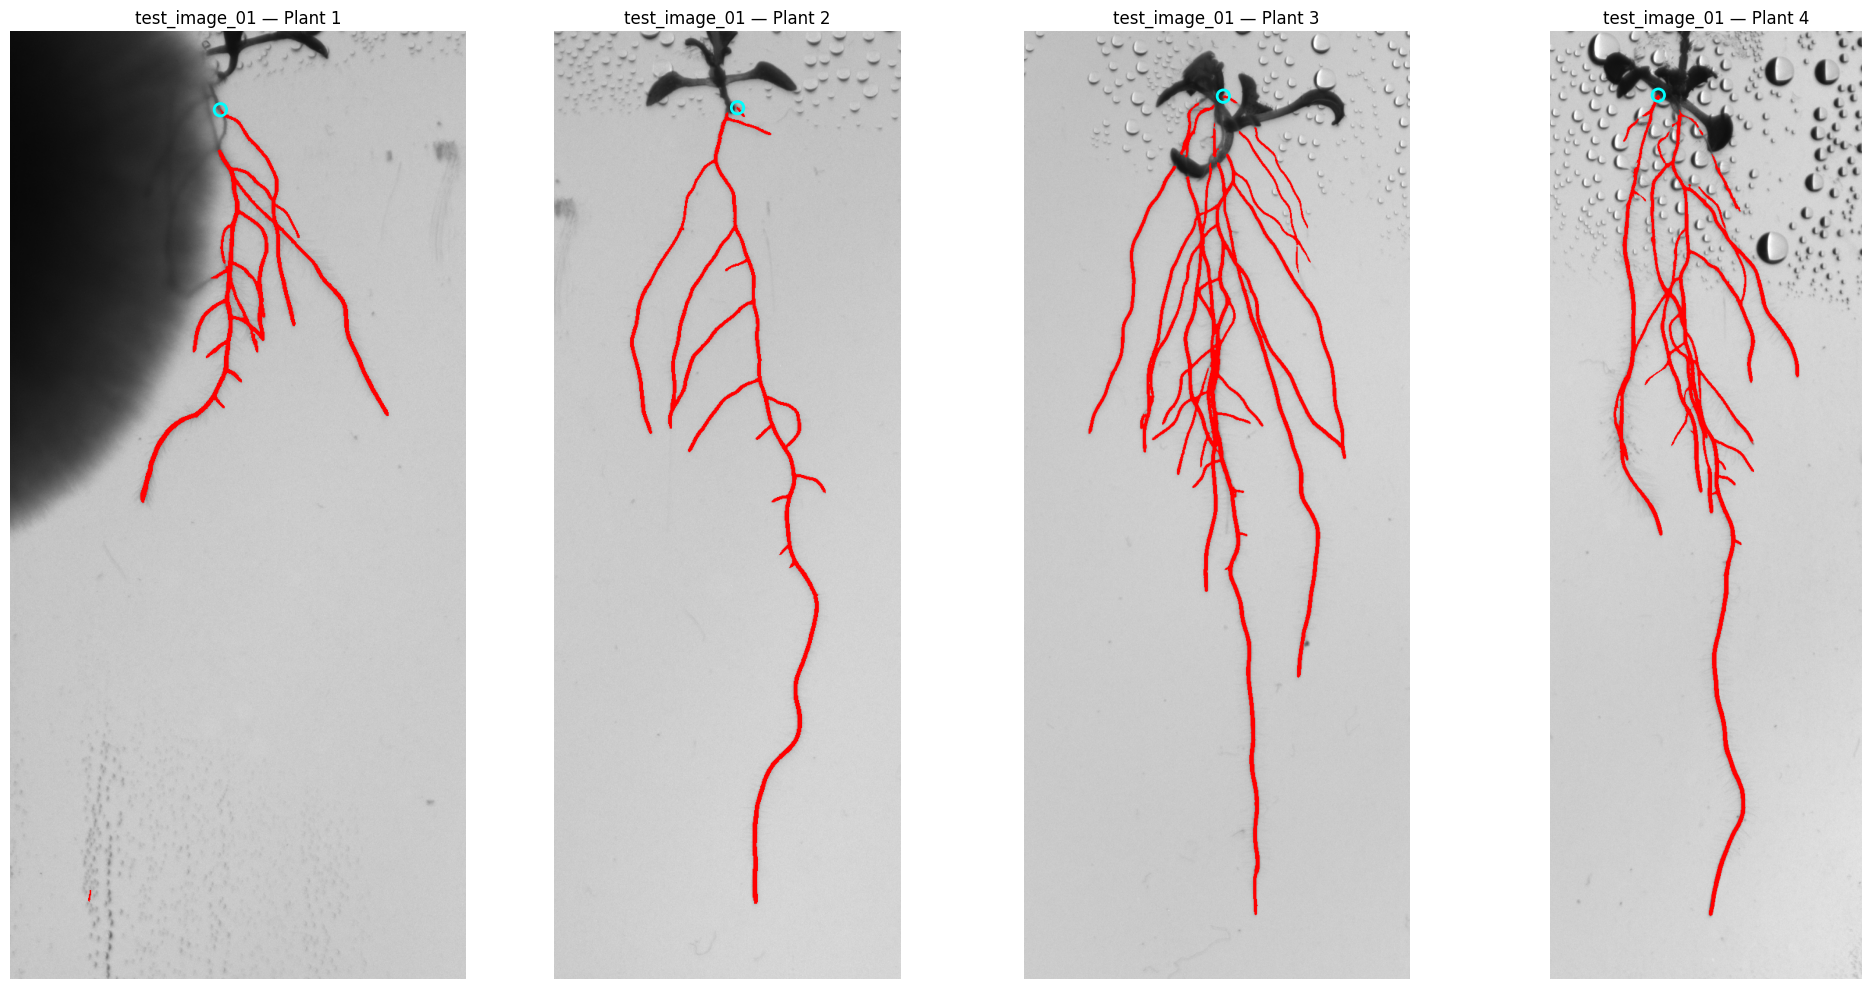

In [17]:
# FULL-RESOLUTION Individual root segmentation CHECK
# Shows individual plants without destroying thin root pixels.

stem = "test_image_01"   # change this if needed

image_path = PETRI_DIR / f"{stem}_petri.png"

bgr = cv2.imread(str(image_path))
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

result = task6_results[stem]

starts = result["starts"]
individual_masks = result["individual_masks"]

fig, axes = plt.subplots(
    1,
    len(starts),
    figsize=(5 * len(starts), 10)
)

if len(starts) == 1:
    axes = [axes]

for ax, (plant_id, x, y) in zip(axes, starts):

    mask = individual_masks[plant_id] > 0

    ys, xs = np.where(mask)

    if len(xs) == 0:
        ax.set_title(f"Plant {plant_id} — EMPTY")
        ax.axis("off")
        continue

    margin = 100

    x0 = max(0, xs.min() - margin)
    x1 = min(rgb.shape[1], xs.max() + margin)

    y0 = max(0, min(y, ys.min()) - margin)
    y1 = min(rgb.shape[0], ys.max() + margin)

    crop = rgb[y0:y1, x0:x1].copy()
    crop_mask = mask[y0:y1, x0:x1]

    overlay = crop.copy()
    overlay[crop_mask] = [255, 0, 0]

    ax.imshow(overlay)

    ax.scatter(
        x - x0,
        y - y0,
        s=80,
        facecolors="none",
        edgecolors="cyan",
        linewidths=2
    )

    ax.set_title(f"{stem} — Plant {plant_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### CHECKPOINT 3 — CURRENT STOP POINT

This is where the project currently stops.

After the Individual root segmentation visualization is confirmed with the corrected U-Net root segmentation inference, the next stage is **Root architecture analysis: extract the primary/main-root trajectory and measure its true geometric length**.

Do not add threshold experiments, RGB-hybrid localization, or the old stride-384/Hann inference back into this notebook.


In [27]:
# ============================================================
# 11. Root architecture analysis — PRIMARY ROOT EXTRACTION
# CORRECTED VERSION
# ============================================================

import cv2
import heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.spatial import cKDTree
from skimage.morphology import skeletonize


TASK7_DIR = OUTPUT_DIR / "07_primary_roots"
TASK7_DIR.mkdir(
    parents=True,
    exist_ok=True
)


ROOT_NEIGHBORS_8 = [
    (-1, -1, np.sqrt(2.0)),
    (-1,  0, 1.0),
    (-1,  1, np.sqrt(2.0)),
    ( 0, -1, 1.0),
    ( 0,  1, 1.0),
    ( 1, -1, np.sqrt(2.0)),
    ( 1,  0, 1.0),
    ( 1,  1, np.sqrt(2.0)),
]


def skeleton_endpoints(skeleton):

    skel_u8 = skeleton.astype(np.uint8)

    neighbour_sum = cv2.filter2D(
        skel_u8,
        ddepth=cv2.CV_16U,
        kernel=np.ones((3, 3), dtype=np.uint8),
        borderType=cv2.BORDER_CONSTANT
    )

    endpoint_mask = (
        (skel_u8 == 1)
        &
        (neighbour_sum == 2)
    )

    return np.column_stack(
        np.where(endpoint_mask)
    )


def nearest_skeleton_pixel(
    skeleton,
    x,
    y
):

    ys, xs = np.where(skeleton)

    if len(xs) == 0:
        return None

    d2 = (
        (xs - int(x)) ** 2
        +
        (ys - int(y)) ** 2
    )

    best = int(np.argmin(d2))

    return (
        int(ys[best]),
        int(xs[best])
    )


def build_virtual_gap_edges(
    skeleton,
    max_gap_px
):

    skeleton_u8 = skeleton.astype(np.uint8)

    n_labels, labels = cv2.connectedComponents(
        skeleton_u8,
        connectivity=8
    )

    if n_labels <= 2:
        return {}, set()

    H, W = skeleton.shape

    effective_gap = max(
        float(max_gap_px),
        220.0,
        0.16 * H
    )

    components = {}

    for label_id in range(
        1,
        n_labels
    ):

        coords = np.column_stack(
            np.where(
                labels == label_id
            )
        )

        if len(coords) > 0:

            components[label_id] = (
                coords.astype(np.int32)
            )


    component_ids = list(
        components.keys()
    )

    trees = {
        label_id:
        cKDTree(
            components[label_id].astype(
                np.float32
            )
        )

        for label_id in component_ids
    }


    virtual_edges = {}
    virtual_pairs = set()


    for i in range(
        len(component_ids)
    ):

        id_a = component_ids[i]
        coords_a = components[id_a]


        for j in range(
            i + 1,
            len(component_ids)
        ):

            id_b = component_ids[j]
            coords_b = components[id_b]


            if len(coords_a) <= len(coords_b):

                distances, indices = (
                    trees[id_b].query(
                        coords_a.astype(
                            np.float32
                        ),
                        k=1
                    )
                )

                best_index = int(
                    np.argmin(distances)
                )

                distance = float(
                    distances[best_index]
                )

                point_a = tuple(
                    map(
                        int,
                        coords_a[best_index]
                    )
                )

                point_b = tuple(
                    map(
                        int,
                        coords_b[
                            int(
                                indices[
                                    best_index
                                ]
                            )
                        ]
                    )
                )

            else:

                distances, indices = (
                    trees[id_a].query(
                        coords_b.astype(
                            np.float32
                        ),
                        k=1
                    )
                )

                best_index = int(
                    np.argmin(distances)
                )

                distance = float(
                    distances[best_index]
                )

                point_b = tuple(
                    map(
                        int,
                        coords_b[best_index]
                    )
                )

                point_a = tuple(
                    map(
                        int,
                        coords_a[
                            int(
                                indices[
                                    best_index
                                ]
                            )
                        ]
                    )
                )


            if distance > effective_gap:
                continue


            y1, x1 = point_a
            y2, x2 = point_b

            dy = abs(y2 - y1)
            dx = abs(x2 - x1)


            # Prevent absurd sideways jumps.
            if dx > max(
                300,
                2.5 * dy + 100
            ):
                continue


            # Only used for selecting a path.
            # NOT used as the final root length.
            selection_cost = (
                1.20
                *
                distance
            )


            virtual_edges.setdefault(
                point_a,
                []
            ).append(
                (
                    point_b,
                    selection_cost
                )
            )

            virtual_edges.setdefault(
                point_b,
                []
            ).append(
                (
                    point_a,
                    selection_cost
                )
            )

            virtual_pairs.add(
                frozenset(
                    (
                        point_a,
                        point_b
                    )
                )
            )


    return (
        virtual_edges,
        virtual_pairs
    )


def dijkstra_on_skeleton(
    skeleton,
    start,
    virtual_edges
):

    h, w = skeleton.shape

    # IMPORTANT:
    # float64 fixes the previous numerical precision bug.
    distances = np.full(
        (h, w),
        np.inf,
        dtype=np.float64
    )

    previous = {}

    sy, sx = start

    distances[
        sy,
        sx
    ] = 0.0

    queue = [
        (
            0.0,
            sy,
            sx
        )
    ]


    while queue:

        dist, y, x = heapq.heappop(
            queue
        )

        # Floating-point safe outdated-entry check.
        if dist > distances[
            y,
            x
        ] + 1e-10:
            continue


        for (
            dy,
            dx,
            step
        ) in ROOT_NEIGHBORS_8:

            ny = y + dy
            nx = x + dx

            if not (
                0 <= ny < h
                and
                0 <= nx < w
                and
                skeleton[
                    ny,
                    nx
                ]
            ):
                continue


            new_dist = (
                dist
                +
                float(step)
            )


            if new_dist < distances[
                ny,
                nx
            ]:

                distances[
                    ny,
                    nx
                ] = new_dist

                previous[
                    (
                        ny,
                        nx
                    )
                ] = (
                    y,
                    x
                )

                heapq.heappush(
                    queue,
                    (
                        new_dist,
                        ny,
                        nx
                    )
                )


        for (
            destination,
            gap_cost
        ) in virtual_edges.get(
            (
                y,
                x
            ),
            []
        ):

            ny, nx = destination

            new_dist = (
                dist
                +
                float(gap_cost)
            )


            if new_dist < distances[
                ny,
                nx
            ]:

                distances[
                    ny,
                    nx
                ] = new_dist

                previous[
                    (
                        ny,
                        nx
                    )
                ] = (
                    y,
                    x
                )

                heapq.heappush(
                    queue,
                    (
                        new_dist,
                        ny,
                        nx
                    )
                )


    return (
        distances,
        previous
    )


def reconstruct_path(
    previous,
    start,
    end
):

    path = [end]

    current = end

    while current != start:

        if current not in previous:
            return None

        current = previous[
            current
        ]

        path.append(
            current
        )


    path.reverse()

    return path


def geometric_path_length(
    path
):

    if (
        path is None
        or
        len(path) < 2
    ):
        return 0.0


    coords = np.asarray(
        path,
        dtype=np.float64
    )

    delta = np.diff(
        coords,
        axis=0
    )


    return float(
        np.hypot(
            delta[:, 0],
            delta[:, 1]
        ).sum()
    )


def extract_primary_root(
    full_mask,
    start_x,
    start_y,
    max_gap_px=180,
    crop_margin=60
):

    binary_full = (
        full_mask > 0
    ).astype(
        np.uint8
    )

    ys, xs = np.where(
        binary_full
    )


    if len(xs) == 0:
        return None


    H, W = binary_full.shape


    x0 = max(
        0,
        int(xs.min()) - crop_margin
    )

    x1 = min(
        W,
        int(xs.max()) + crop_margin + 1
    )


    y0 = max(
        0,
        min(
            int(ys.min()),
            int(start_y)
        )
        -
        crop_margin
    )

    y1 = min(
        H,
        int(ys.max()) + crop_margin + 1
    )


    binary = binary_full[
        y0:y1,
        x0:x1
    ]


    skeleton = skeletonize(
        binary.astype(bool)
    )


    thickness = cv2.distanceTransform(
        binary,
        cv2.DIST_L2,
        5
    )


    local_start = (
        nearest_skeleton_pixel(
            skeleton,
            int(start_x) - x0,
            int(start_y) - y0
        )
    )


    if local_start is None:
        return None


    (
        virtual_edges,
        virtual_pairs
    ) = build_virtual_gap_edges(
        skeleton,
        max_gap_px
    )


    (
        distances,
        previous
    ) = dijkstra_on_skeleton(
        skeleton,
        local_start,
        virtual_edges
    )


    endpoints = skeleton_endpoints(
        skeleton
    )

    reachable = []


    for ey, ex in endpoints:

        ey = int(ey)
        ex = int(ex)


        if not np.isfinite(
            distances[
                ey,
                ex
            ]
        ):
            continue


        if (
            ey,
            ex
        ) == local_start:
            continue


        vertical_gain = (
            ey
            -
            local_start[0]
        )


        if vertical_gain <= 10:
            continue


        path = reconstruct_path(
            previous,
            local_start,
            (
                ey,
                ex
            )
        )


        if path is None:
            continue


        true_length = (
            geometric_path_length(
                path
            )
        )


        vertical_efficiency = (
            vertical_gain
            /
            max(
                true_length,
                1e-6
            )
        )


        path_array = np.asarray(
            path,
            dtype=np.int32
        )


        lower_start = int(
            0.35
            *
            len(path_array)
        )


        lower_path = path_array[
            lower_start:
        ]


        lower_thickness = thickness[
            lower_path[:, 0],
            lower_path[:, 1]
        ]


        path_thickness = float(
            np.median(
                lower_thickness
            )
        )


        reachable.append({
            "endpoint": (
                ey,
                ex
            ),

            "path":
                path,

            "depth":
                float(
                    vertical_gain
                ),

            "length":
                float(
                    true_length
                ),

            "vertical_efficiency":
                float(
                    vertical_efficiency
                ),

            "thickness":
                path_thickness
        })


    if len(reachable) == 0:
        return None


    robust_bottom = int(
        np.percentile(
            ys,
            99.5
        )
    )


    root_span = max(
        1,
        robust_bottom
        -
        int(start_y)
    )


    max_depth = max(
        item["depth"]
        for item in reachable
    )


    depth_band = max(
        20,
        int(
            0.08
            *
            root_span
        )
    )


    deep_candidates = [
        item

        for item in reachable

        if item["depth"]
        >=
        max_depth
        -
        depth_band
    ]


    max_candidate_length = max(
        item["length"]
        for item in deep_candidates
    )


    max_candidate_thickness = max(
        item["thickness"]
        for item in deep_candidates
    )


    candidate_scores = []


    for item in deep_candidates:

        depth_ratio = np.clip(
            item["depth"]
            /
            max(
                root_span,
                1
            ),
            0.0,
            1.10
        )


        length_ratio = (
            item["length"]
            /
            max(
                max_candidate_length,
                1e-6
            )
        )


        thickness_ratio = (
            item["thickness"]
            /
            max(
                max_candidate_thickness,
                1e-6
            )
        )


        efficiency = np.clip(
            item[
                "vertical_efficiency"
            ],
            0.0,
            1.0
        )


        score = (
            0.45
            *
            depth_ratio
            +
            0.25
            *
            efficiency
            +
            0.15
            *
            length_ratio
            +
            0.15
            *
            thickness_ratio
        )


        candidate_scores.append(
            float(score)
        )


    best_index = int(
        np.argmax(
            candidate_scores
        )
    )


    best = deep_candidates[
        best_index
    ]


    path_local = best[
        "path"
    ]


    path_global = np.array(
        [
            (
                int(py + y0),
                int(px + x0)
            )

            for py, px
            in path_local
        ],
        dtype=np.int32
    )


    used_gaps = []


    for a, b in zip(
        path_local[:-1],
        path_local[1:]
    ):

        if frozenset(
            (
                a,
                b
            )
        ) in virtual_pairs:

            used_gaps.append(
                (
                    a,
                    b,
                    float(
                        np.hypot(
                            b[0] - a[0],
                            b[1] - a[1]
                        )
                    )
                )
            )


    tip_y = int(
        path_global[
            -1,
            0
        ]
    )

    tip_x = int(
        path_global[
            -1,
            1
        ]
    )


    mask_bottom = robust_bottom


    remaining_to_bottom = (
        mask_bottom
        -
        tip_y
    )


    status = (
        "OK"

        if remaining_to_bottom
        <=
        max(
            25,
            int(
                0.05
                *
                root_span
            )
        )

        else "CHECK"
    )


    return {

        "path":
            path_global,

        "length_px":
            float(
                best[
                    "length"
                ]
            ),

        "start": (
            int(
                path_global[
                    0,
                    1
                ]
            ),
            int(
                path_global[
                    0,
                    0
                ]
            )
        ),

        "tip": (
            tip_x,
            tip_y
        ),

        "gap_count":
            len(
                used_gaps
            ),

        "gap_edges":
            used_gaps,

        "candidate_count":
            len(
                deep_candidates
            ),

        "status":
            status,

        "mask_bottom_y":
            mask_bottom,

        "tip_depth_px":
            float(
                best[
                    "depth"
                ]
            ),

        "vertical_efficiency":
            float(
                best[
                    "vertical_efficiency"
                ]
            )
    }


print(
    "✅ Corrected Task 7 functions ready."
)

✅ Corrected Task 7 functions ready.


In [30]:
# ============================================================
# 12. Root architecture analysis — RUN ON ALL IMAGES
# CORRECTED GAP SCALE
# ============================================================

task7_results = {}
task7_records = []


for image_path in petri_images:

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    result6 = task6_results[stem]

    starts = result6["starts"]
    individual_masks = result6["individual_masks"]
    owner_map = result6["owner_map"]

    H, W = owner_map.shape

    # IMPORTANT:
    # Match the gap scale already accepted by Individual root segmentation.
    # These masks are already separated by plant, so bridging
    # fragments here cannot jump into another plant.
    max_gap_px = max(
        130,
        int(H * 0.065)
    )

    image_dir = TASK7_DIR / stem

    image_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    task7_results[stem] = {}

    print(
        f"\n{stem} | "
        f"max gap = {max_gap_px}px"
    )


    for (
        plant_id,
        start_x,
        start_y
    ) in starts:

        plant_id = int(plant_id)

        mask = individual_masks[plant_id]

        primary = extract_primary_root(
            full_mask=mask,
            start_x=int(start_x),
            start_y=int(start_y),
            max_gap_px=max_gap_px
        )

        task7_results[stem][plant_id] = primary


        if primary is None:

            print(
                f"  plant {plant_id}: FAILED"
            )

            task7_records.append({
                "image": stem,
                "plant": plant_id,
                "length_px": np.nan,
                "start_x": int(start_x),
                "start_y": int(start_y),
                "tip_x": np.nan,
                "tip_y": np.nan,
                "gap_count": np.nan,
                "vertical_efficiency": np.nan,
                "status": "FAILED"
            })

            continue


        np.save(
            image_dir
            / f"plant_{plant_id:02d}_primary_path_yx.npy",
            primary["path"]
        )


        task7_records.append({
            "image": stem,
            "plant": plant_id,
            "length_px": primary["length_px"],
            "start_x": primary["start"][0],
            "start_y": primary["start"][1],
            "tip_x": primary["tip"][0],
            "tip_y": primary["tip"][1],
            "gap_count": primary["gap_count"],
            "vertical_efficiency": primary[
                "vertical_efficiency"
            ],
            "status": primary["status"]
        })


        print(
            f"  plant {plant_id}: "
            f"{primary['length_px']:.1f}px | "
            f"gaps={primary['gap_count']} | "
            f"{primary['status']}"
        )


task7_df = pd.DataFrame(
    task7_records
)

task7_df.to_csv(
    TASK7_DIR
    / "primary_root_lengths.csv",
    index=False
)


print()
print(
    "Task 7 complete:",
    len(task7_df),
    "plants"
)

print()

print(
    task7_df["status"].value_counts(
        dropna=False
    )
)

display(task7_df)


test_image_01 | max gap = 180px
  plant 1: 716.1px | gaps=0 | OK
  plant 2: 1186.0px | gaps=1 | OK
  plant 3: 1350.6px | gaps=2 | OK
  plant 4: 1569.8px | gaps=3 | OK

test_image_02 | max gap = 180px
  plant 1: 1001.4px | gaps=0 | OK
  plant 2: 1238.6px | gaps=0 | OK
  plant 3: 930.6px | gaps=0 | OK
  plant 4: 991.7px | gaps=0 | OK
  plant 5: 983.0px | gaps=0 | OK

test_image_03 | max gap = 180px
  plant 1: 100.8px | gaps=0 | CHECK
  plant 2: 128.9px | gaps=0 | CHECK
  plant 3: 18.1px | gaps=0 | CHECK

test_image_04 | max gap = 178px
  plant 1: 223.0px | gaps=1 | OK
  plant 2: 1130.5px | gaps=1 | OK
  plant 3: 1020.8px | gaps=0 | OK
  plant 4: 1063.4px | gaps=1 | CHECK
  plant 5: 1113.3px | gaps=0 | OK

test_image_05 | max gap = 178px
  plant 1: 134.2px | gaps=0 | OK
  plant 2: 32.1px | gaps=0 | OK
  plant 3: 82.5px | gaps=0 | OK
  plant 4: 16.4px | gaps=0 | OK

test_image_06 | max gap = 178px
  plant 1: 248.3px | gaps=0 | OK
  plant 2: 226.4px | gaps=0 | OK
  plant 3: 44.2px | gaps=0

,image,plant,length_px,start_x,start_y,tip_x,tip_y,gap_count,vertical_efficiency,status
0,test_image_01,1,716.097546,364,551,265,1052,0,0.699625,OK
1,test_image_01,2,1185.999565,880,472,904,1517,1,0.881113,OK
2,test_image_01,3,1350.643427,1907,502,1956,1767,2,0.936591,OK
3,test_image_01,4,1569.793992,2387,482,2470,1766,3,0.817942,OK
4,test_image_02,1,1001.416306,332,465,408,1396,0,0.929683,OK
...,...,...,...,...,...,...,...,...,...,...
82,test_image_19,1,285.982756,356,534,397,803,0,0.940616,OK
83,test_image_19,2,284.740115,880,512,890,781,0,0.944721,CHECK
84,test_image_19,3,320.923882,1397,512,1356,806,0,0.916105,OK
85,test_image_19,4,340.811183,1900,492,1881,815,0,0.947739,OK


In [29]:
# ============================================================
# Root architecture analysis DIAGNOSTIC ONLY — DO NOT MODIFY ANYTHING
# ============================================================

stem = "test_image_01"
plant_id = 2

result6 = task6_results[stem]
mask = (result6["individual_masks"][plant_id] > 0).astype(np.uint8)

start_record = [
    s for s in result6["starts"]
    if int(s[0]) == plant_id
][0]

_, start_x, start_y = start_record

ys, xs = np.where(mask)

H, W = mask.shape

x0 = max(0, int(xs.min()) - 60)
x1 = min(W, int(xs.max()) + 61)

y0 = max(
    0,
    min(int(ys.min()), int(start_y)) - 60
)

y1 = min(
    H,
    int(ys.max()) + 61
)

binary = mask[y0:y1, x0:x1]

skeleton = skeletonize(
    binary.astype(bool)
)

local_start = nearest_skeleton_pixel(
    skeleton,
    int(start_x) - x0,
    int(start_y) - y0
)

n_labels, labels = cv2.connectedComponents(
    skeleton.astype(np.uint8),
    connectivity=8
)

endpoints = skeleton_endpoints(
    skeleton
)

virtual_edges, virtual_pairs = build_virtual_gap_edges(
    skeleton,
    180
)

distances, previous = dijkstra_on_skeleton(
    skeleton,
    local_start,
    virtual_edges
)

reachable_pixels = (
    skeleton
    &
    np.isfinite(distances)
)

reachable_endpoints = []

deep_reachable_endpoints = []

for ey, ex in endpoints:

    ey = int(ey)
    ex = int(ex)

    if np.isfinite(distances[ey, ex]):

        reachable_endpoints.append(
            (ey, ex)
        )

        if ey - local_start[0] > 10:

            deep_reachable_endpoints.append(
                (ey, ex)
            )


print("MASK PIXELS:", int(mask.sum()))
print("SKELETON PIXELS:", int(skeleton.sum()))

print()
print("SKELETON COMPONENTS:", n_labels - 1)
print("VIRTUAL BRIDGES:", len(virtual_pairs))

print()
print("V5.1 START:", (start_x, start_y))
print("SNAPPED START:", local_start)

print()
print("TOTAL ENDPOINTS:", len(endpoints))
print("REACHABLE ENDPOINTS:", len(reachable_endpoints))
print("DEEP REACHABLE ENDPOINTS:", len(deep_reachable_endpoints))

print()
print(
    "DEEPEST SKELETON Y:",
    int(np.where(skeleton)[0].max())
)

if reachable_pixels.any():

    print(
        "DEEPEST REACHABLE Y:",
        int(np.where(reachable_pixels)[0].max())
    )

print()
print(
    "START COMPONENT:",
    int(labels[local_start])
)

MASK PIXELS: 11622
SKELETON PIXELS: 2220

SKELETON COMPONENTS: 2
VIRTUAL BRIDGES: 1

V5.1 START: (881, 472)
SNAPPED START: (60, 200)

TOTAL ENDPOINTS: 15
REACHABLE ENDPOINTS: 15
DEEP REACHABLE ENDPOINTS: 13

DEEPEST SKELETON Y: 1105
DEEPEST REACHABLE Y: 1105

START COMPONENT: 1


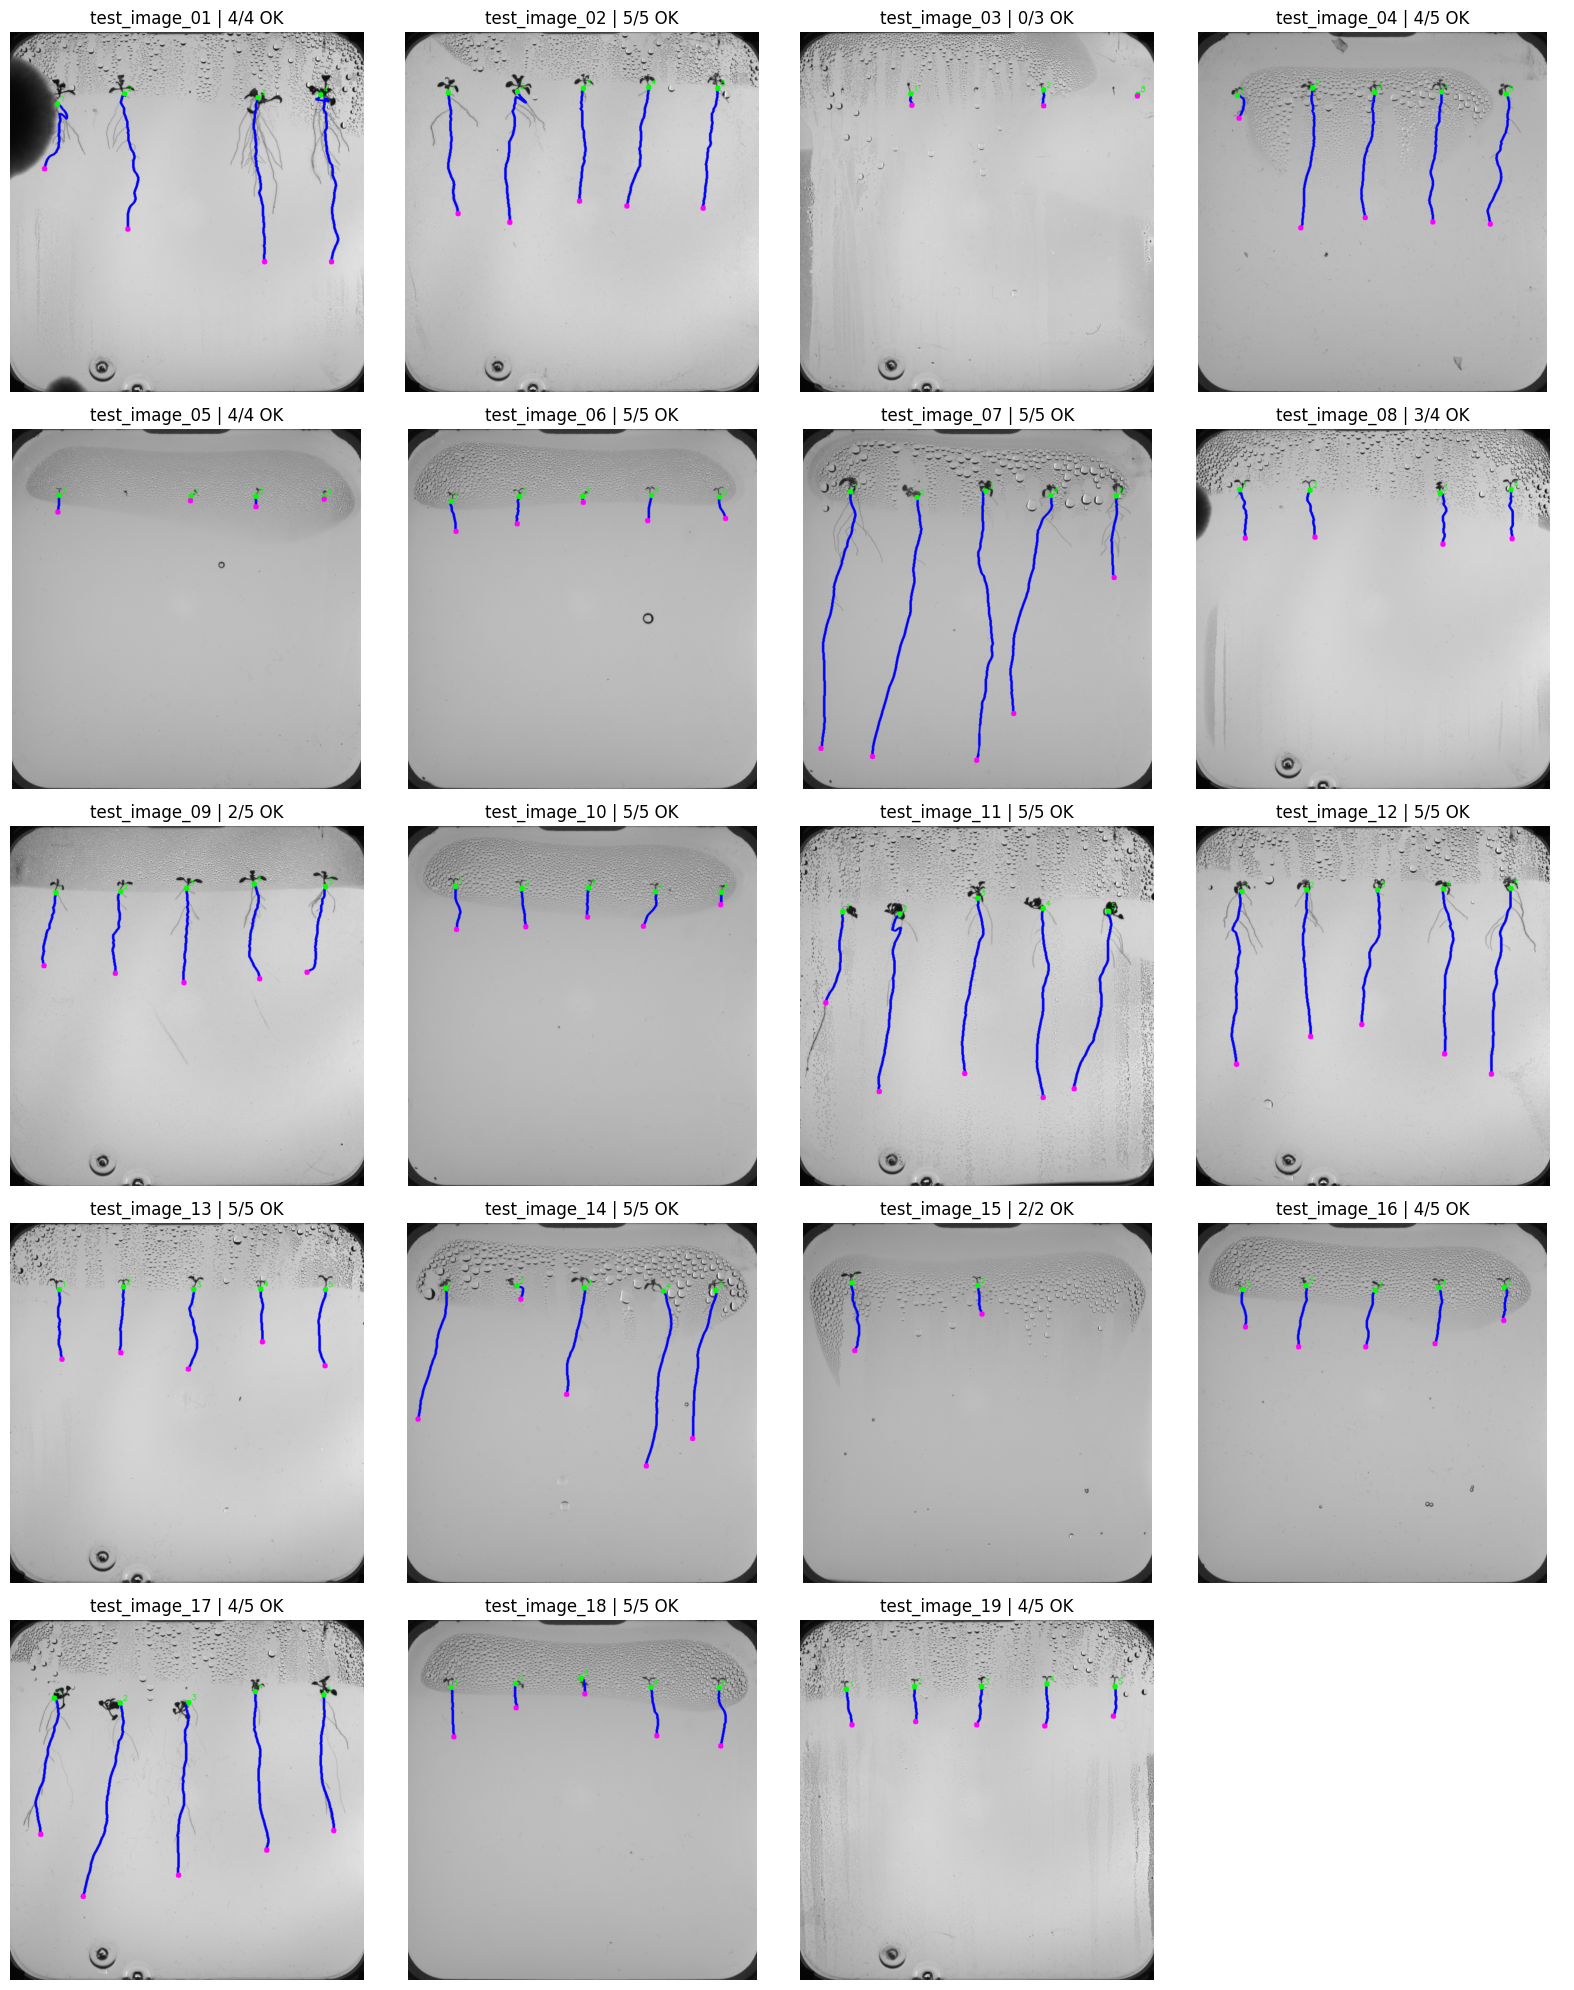

Plants needing inspection: 11


,image,plant,length_px,start_x,start_y,tip_x,tip_y,gap_count,vertical_efficiency,status
9,test_image_03,1,100.769553,850,473,860,563,0,0.893127,CHECK
10,test_image_03,2,128.941125,1872,445,1874,564,0,0.922902,CHECK
11,test_image_03,3,18.071068,2599,476,2594,492,0,0.885393,CHECK
15,test_image_04,4,1063.375774,1854,456,1787,1444,1,0.929117,CHECK
31,test_image_08,1,423.693434,334,466,377,840,0,0.882714,CHECK
36,test_image_09,2,685.161472,849,504,809,1132,0,0.916572,CHECK
37,test_image_09,3,771.826563,1358,477,1337,1202,1,0.939330,CHECK
38,test_image_09,4,812.428499,1878,443,1918,1172,0,0.897310,CHECK
69,test_image_16,3,472.563492,1350,513,1278,940,0,0.903582,CHECK
73,test_image_17,2,1635.146320,848,636,561,2126,0,0.911233,CHECK


In [31]:
# ============================================================
# 13. Root architecture analysis — FINAL VISUAL CHECK
# ============================================================

cols = 4

rows = int(
    np.ceil(
        len(
            petri_images
        )
        /
        cols
    )
)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(
        16,
        4 * rows
    )
)

axes = np.asarray(
    axes
).ravel()


for ax, image_path in zip(
    axes,
    petri_images
):

    stem = image_path.stem.replace(
        "_petri",
        ""
    )

    bgr = cv2.imread(
        str(
            image_path
        ),
        cv2.IMREAD_COLOR
    )

    H, W = bgr.shape[:2]

    display_width = 650

    scale = min(
        1.0,
        display_width
        /
        W
    )

    display_size = (
        int(
            W * scale
        ),
        int(
            H * scale
        )
    )

    display_image = cv2.resize(
        bgr,
        display_size,
        interpolation=cv2.INTER_AREA
    )

    results = task7_results[
        stem
    ]

    ok_count = 0


    for plant_id in sorted(
        results
    ):

        result = results[
            plant_id
        ]

        if result is None:
            continue

        path = result[
            "path"
        ]

        pts = np.column_stack(
            (
                path[:, 1]
                *
                scale,

                path[:, 0]
                *
                scale
            )
        )

        pts = np.round(
            pts
        ).astype(
            np.int32
        ).reshape(
            -1,
            1,
            2
        )


        # BLUE = primary root
        cv2.polylines(
            display_image,
            [
                pts
            ],
            isClosed=False,
            color=(
                255,
                0,
                0
            ),
            thickness=2,
            lineType=cv2.LINE_AA
        )


        start_x, start_y = result[
            "start"
        ]

        tip_x, tip_y = result[
            "tip"
        ]


        start_pt = (
            int(
                round(
                    start_x
                    *
                    scale
                )
            ),
            int(
                round(
                    start_y
                    *
                    scale
                )
            )
        )

        tip_pt = (
            int(
                round(
                    tip_x
                    *
                    scale
                )
            ),
            int(
                round(
                    tip_y
                    *
                    scale
                )
            )
        )


        # GREEN = start
        cv2.circle(
            display_image,
            start_pt,
            5,
            (
                0,
                255,
                0
            ),
            -1
        )


        # MAGENTA = selected tip
        cv2.circle(
            display_image,
            tip_pt,
            5,
            (
                255,
                0,
                255
            ),
            -1
        )


        cv2.putText(
            display_image,
            str(
                plant_id
            ),
            (
                start_pt[0] + 5,
                start_pt[1] - 5
            ),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            (
                0,
                255,
                0
            ),
            1,
            cv2.LINE_AA
        )


        if result[
            "status"
        ] == "OK":

            ok_count += 1


    rgb = cv2.cvtColor(
        display_image,
        cv2.COLOR_BGR2RGB
    )

    ax.imshow(
        rgb
    )

    ax.set_title(
        f"{stem} | "
        f"{ok_count}/{len(results)} OK"
    )

    ax.axis(
        "off"
    )


for ax in axes[
    len(
        petri_images
    ):
]:

    ax.axis(
        "off"
    )


plt.tight_layout()
plt.show()


flagged = task7_df[
    task7_df[
        "status"
    ]
    !=
    "OK"
]


print(
    "Plants needing inspection:",
    len(
        flagged
    )
)


if len(
    flagged
) > 0:

    display(
        flagged
    )

else:

    print(
        "✅ No automatic Task 7 warnings."
    )

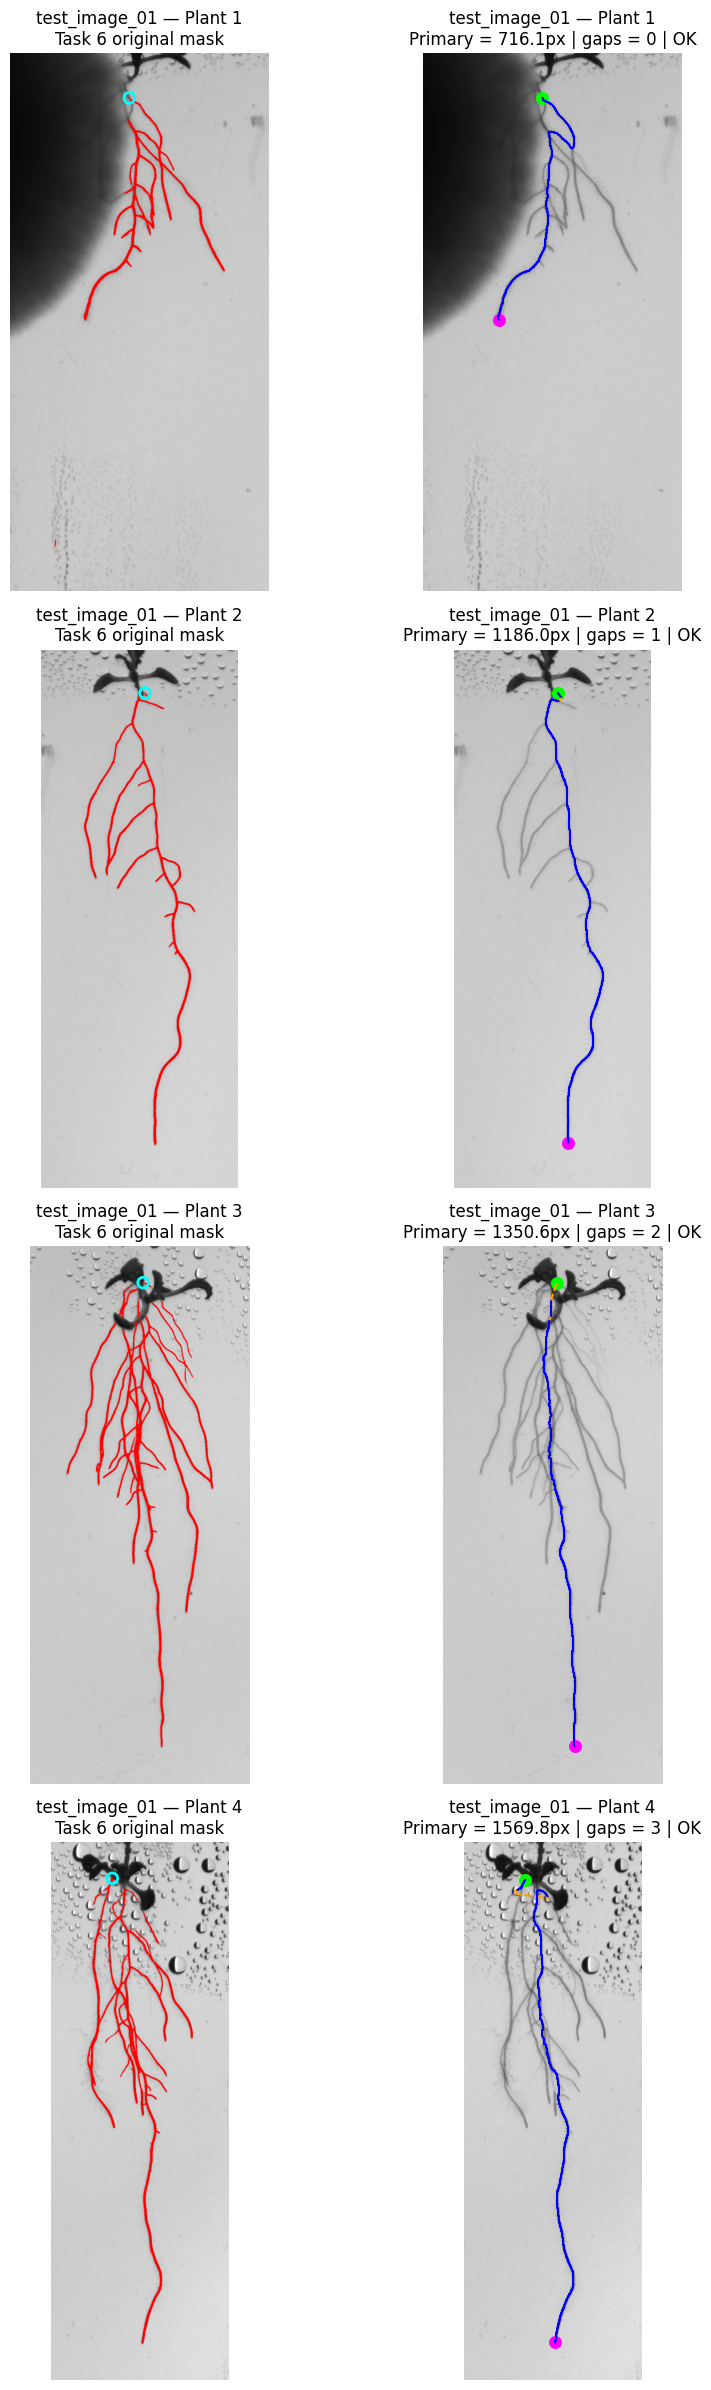

In [33]:
# ============================================================
# Root architecture analysis SANITY CHECK — Individual root segmentation MASK VS PRIMARY ROOT
# ============================================================

def compare_task6_task7(stem):

    image_path = PETRI_DIR / f"{stem}_petri.png"

    bgr = cv2.imread(str(image_path))
    rgb = cv2.cvtColor(
        bgr,
        cv2.COLOR_BGR2RGB
    )

    result6 = task6_results[stem]
    result7 = task7_results[stem]

    starts = result6["starts"]
    individual_masks = result6["individual_masks"]

    n_plants = len(starts)

    fig, axes = plt.subplots(
        n_plants,
        2,
        figsize=(10, 6 * n_plants)
    )

    if n_plants == 1:
        axes = np.array([axes])


    for row, (
        plant_id,
        start_x,
        start_y
    ) in enumerate(starts):

        plant_id = int(plant_id)

        mask = (
            individual_masks[plant_id] > 0
        )

        ys, xs = np.where(mask)

        if len(xs) == 0:
            continue


        margin = 100

        x0 = max(
            0,
            int(xs.min()) - margin
        )

        x1 = min(
            rgb.shape[1],
            int(xs.max()) + margin + 1
        )

        y0 = max(
            0,
            min(
                int(ys.min()),
                int(start_y)
            ) - margin
        )

        y1 = min(
            rgb.shape[0],
            int(ys.max()) + margin + 1
        )


        crop = rgb[
            y0:y1,
            x0:x1
        ].copy()

        crop_mask = mask[
            y0:y1,
            x0:x1
        ]


        # ====================================================
        # LEFT — ORIGINAL Individual root segmentation MASK
        # ====================================================

        left = crop.copy()

        left[
            crop_mask
        ] = [255, 0, 0]

        axes[row, 0].imshow(left)

        axes[row, 0].scatter(
            int(start_x) - x0,
            int(start_y) - y0,
            s=60,
            facecolors="none",
            edgecolors="cyan",
            linewidths=2
        )

        axes[row, 0].set_title(
            f"{stem} — Plant {plant_id}\n"
            "Task 6 original mask"
        )

        axes[row, 0].axis("off")


        # ====================================================
        # RIGHT — Root architecture analysis PRIMARY ROOT
        # ====================================================

        axes[row, 1].imshow(crop)

        primary = result7.get(
            plant_id
        )


        if primary is None:

            axes[row, 1].set_title(
                f"{stem} — Plant {plant_id}\nFAILED"
            )

            axes[row, 1].axis("off")
            continue


        path = primary["path"]

        local_x = (
            path[:, 1] - x0
        )

        local_y = (
            path[:, 0] - y0
        )


        # Plot segment-by-segment so virtual jumps
        # are visibly different from real skeleton travel.
        for i in range(
            len(path) - 1
        ):

            y_a, x_a = path[i]
            y_b, x_b = path[i + 1]

            jump = np.hypot(
                y_b - y_a,
                x_b - x_a
            )


            if jump > 1.5:

                # Virtual gap bridge
                axes[row, 1].plot(
                    [
                        x_a - x0,
                        x_b - x0
                    ],
                    [
                        y_a - y0,
                        y_b - y0
                    ],
                    linestyle="--",
                    linewidth=1.5,
                    color="orange"
                )

            else:

                # Real skeleton pixels
                axes[row, 1].plot(
                    [
                        x_a - x0,
                        x_b - x0
                    ],
                    [
                        y_a - y0,
                        y_b - y0
                    ],
                    linewidth=1.2,
                    color="blue"
                )


        start = primary["start"]
        tip = primary["tip"]


        axes[row, 1].scatter(
            start[0] - x0,
            start[1] - y0,
            s=70,
            color="lime"
        )

        axes[row, 1].scatter(
            tip[0] - x0,
            tip[1] - y0,
            s=70,
            color="magenta"
        )


        axes[row, 1].set_title(
            f"{stem} — Plant {plant_id}\n"
            f"Primary = {primary['length_px']:.1f}px | "
            f"gaps = {primary['gap_count']} | "
            f"{primary['status']}"
        )

        axes[row, 1].axis("off")


    plt.tight_layout()
    plt.show()


# ============================================================
# CHANGE ONLY THIS IMAGE NAME
# ============================================================

compare_task6_task7(
    "test_image_01"
)

In [34]:
# ============================================================
# Root-length prediction — FINAL KAGGLE SUBMISSION
# ============================================================

import re
import zipfile
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.optimize import linear_sum_assignment


KAGGLE_ZIP = Path(
    "/home/y2a/Kaggle (1).zip"
)

SUBMISSION_DIR = OUTPUT_DIR / "08_submission"
SUBMISSION_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 1. LOAD THE REAL SAMPLE SUBMISSION
# ============================================================

sample_path = Path(
    "/home/y2a/sample_submission.csv"
)

if sample_path.exists():

    sample_df = pd.read_csv(
        sample_path
    )

else:

    if not KAGGLE_ZIP.exists():

        raise FileNotFoundError(
            f"Could not find {KAGGLE_ZIP}"
        )

    with zipfile.ZipFile(
        KAGGLE_ZIP,
        "r"
    ) as z:

        candidates = [
            name
            for name in z.namelist()
            if Path(name).name
            ==
            "sample_submission.csv"
        ]

        if len(candidates) == 0:

            raise FileNotFoundError(
                "sample_submission.csv "
                "was not found inside the Kaggle ZIP."
            )

        sample_member = candidates[0]

        with z.open(
            sample_member
        ) as f:

            sample_df = pd.read_csv(
                f
            )


# Exact Kaggle format check

assert list(
    sample_df.columns
) == [
    "Plant ID",
    "Length (px)"
]

assert len(
    sample_df
) == 95

assert sample_df[
    "Plant ID"
].nunique() == 95


print(
    "✅ Sample submission loaded:"
)

print(
    len(sample_df),
    "rows"
)


# ============================================================
# 2. LEARN THE FIVE NORMAL LEFT-TO-RIGHT SLOT POSITIONS
# ============================================================

five_root_images = []


for stem, result6 in task6_results.items():

    starts = result6["starts"]

    if len(starts) != 5:
        continue

    width = result6[
        "owner_map"
    ].shape[1]

    xs = sorted(
        [
            float(start[1])
            /
            float(width)

            for start in starts
        ]
    )

    five_root_images.append(
        xs
    )


if len(five_root_images) == 0:

    raise RuntimeError(
        "Could not learn the five plant positions."
    )


canonical_slots = np.median(
    np.asarray(
        five_root_images,
        dtype=np.float64
    ),
    axis=0
)


print()
print(
    "Canonical five plant positions:"
)

for slot, x in enumerate(
    canonical_slots,
    start=1
):

    print(
        f"plant_{slot}: "
        f"x={x:.4f}"
    )


# ============================================================
# 3. MAP EVERY DETECTED ROOT INTO ONE OF THE FIVE FIXED SLOTS
# ============================================================

lengths_by_image = {}

mapping_records = []


expected_images = [
    f"test_image_{i:02d}"
    for i in range(
        1,
        20
    )
]


for stem in expected_images:

    if stem not in task6_results:

        raise KeyError(
            f"Missing Task 6 result: {stem}"
        )

    if stem not in task7_results:

        raise KeyError(
            f"Missing Task 7 result: {stem}"
        )


    result6 = task6_results[
        stem
    ]

    starts = result6[
        "starts"
    ]

    width = result6[
        "owner_map"
    ].shape[1]


    # Five Kaggle positions always exist.
    # Missing roots remain 0.
    slot_lengths = np.zeros(
        5,
        dtype=np.float64
    )


    detected = []


    for (
        internal_plant_id,
        start_x,
        start_y
    ) in starts:

        internal_plant_id = int(
            internal_plant_id
        )

        primary = task7_results[
            stem
        ].get(
            internal_plant_id
        )


        if primary is None:

            raise RuntimeError(
                f"{stem} plant "
                f"{internal_plant_id} "
                "has no Task 7 result."
            )


        detected.append({
            "internal_id":
                internal_plant_id,

            "start_x":
                int(start_x),

            "x_norm":
                float(start_x)
                /
                float(width),

            "length_px":
                float(
                    primary[
                        "length_px"
                    ]
                )
        })


    if len(detected) > 0:

        detected_x = np.asarray(
            [
                item[
                    "x_norm"
                ]

                for item
                in detected
            ],
            dtype=np.float64
        )


        # Distance from every detected root
        # to every one of the five physical slots.
        cost_matrix = np.abs(
            detected_x[:, None]
            -
            canonical_slots[
                None,
                :
            ]
        )


        detected_indices, slot_indices = (
            linear_sum_assignment(
                cost_matrix
            )
        )


        for detected_idx, slot_idx in zip(
            detected_indices,
            slot_indices
        ):

            item = detected[
                detected_idx
            ]

            error = float(
                cost_matrix[
                    detected_idx,
                    slot_idx
                ]
            )


            slot_lengths[
                slot_idx
            ] = item[
                "length_px"
            ]


            mapping_records.append({
                "image":
                    stem,

                "internal_plant":
                    item[
                        "internal_id"
                    ],

                "kaggle_plant":
                    int(
                        slot_idx + 1
                    ),

                "start_x":
                    item[
                        "start_x"
                    ],

                "x_norm":
                    item[
                        "x_norm"
                    ],

                "slot_x_norm":
                    float(
                        canonical_slots[
                            slot_idx
                        ]
                    ),

                "slot_error":
                    error,

                "length_px":
                    item[
                        "length_px"
                    ]
            })


    lengths_by_image[
        stem
    ] = slot_lengths


# ============================================================
# 4. BUILD EXACT 95-ROW SUBMISSION
# ============================================================

submission = sample_df.copy()

predictions = []


pattern = re.compile(
    r"^(test_image_\d{2})_plant_([1-5])$"
)


for plant_id in submission[
    "Plant ID"
]:

    match = pattern.match(
        str(
            plant_id
        )
    )


    if match is None:

        raise ValueError(
            f"Unexpected Plant ID: {plant_id}"
        )


    stem = match.group(1)

    plant_number = int(
        match.group(2)
    )


    prediction = (
        lengths_by_image[
            stem
        ][
            plant_number - 1
        ]
    )


    predictions.append(
        float(
            prediction
        )
    )


submission[
    "Length (px)"
] = predictions


# ============================================================
# 5. VALIDATION
# ============================================================

assert len(
    submission
) == 95

assert submission[
    "Plant ID"
].nunique() == 95

assert submission[
    "Length (px)"
].notna().all()

assert (
    submission[
        "Length (px)"
    ] >= 0
).all()


total_detected_roots = sum(
    len(
        task6_results[
            stem
        ][
            "starts"
        ]
    )

    for stem
    in expected_images
)


expected_zero_slots = (
    95
    -
    total_detected_roots
)


actual_zero_slots = int(
    (
        submission[
            "Length (px)"
        ]
        ==
        0
    ).sum()
)


assert (
    actual_zero_slots
    ==
    expected_zero_slots
), (
    f"Expected {expected_zero_slots} "
    f"zero slots but found "
    f"{actual_zero_slots}."
)


# ============================================================
# 6. SAVE AUDIT TABLE + SUBMISSION
# ============================================================

mapping_df = pd.DataFrame(
    mapping_records
)


mapping_df.to_csv(
    SUBMISSION_DIR
    /
    "plant_slot_mapping.csv",
    index=False
)


submission_path = (
    SUBMISSION_DIR
    /
    "submission_task8.csv"
)


submission.to_csv(
    submission_path,
    index=False
)


# ============================================================
# 7. FINAL SANITY REPORT
# ============================================================

print()
print(
    "============================================"
)

print(
    "✅ FINAL KAGGLE SUBMISSION READY"
)

print(
    "============================================"
)

print(
    "Images:",
    len(
        expected_images
    )
)

print(
    "Detected germinated roots:",
    total_detected_roots
)

print(
    "Non-germinated / zero slots:",
    actual_zero_slots
)

print(
    "Total predictions:",
    len(
        submission
    )
)

print()
print(
    "Saved:",
    submission_path
)


print()
print(
    "Predictions by image:"
)


for stem in expected_images:

    values = lengths_by_image[
        stem
    ]

    print(
        stem,
        "->",
        [
            round(
                float(v),
                1
            )
            for v in values
        ]
    )


print()
print(
    "Zero-valued Plant IDs:"
)

display(
    submission[
        submission[
            "Length (px)"
        ]
        ==
        0
    ]
)


print()
print(
    "Slot mapping:"
)

display(
    mapping_df
)


print()
print(
    "Submission preview:"
)

display(
    submission.head(
        15
    )
)

✅ Sample submission loaded:
95 rows

Canonical five plant positions:
plant_1: x=0.1261
plant_2: x=0.3154
plant_3: x=0.5060
plant_4: x=0.6968
plant_5: x=0.8893

✅ FINAL KAGGLE SUBMISSION READY
Images: 19
Detected germinated roots: 87
Non-germinated / zero slots: 8
Total predictions: 95

Saved: /home/y2a/task8_clean_pipeline/outputs/08_submission/submission_task8.csv

Predictions by image:
test_image_01 -> [716.1, 1186.0, 0.0, 1350.6, 1569.8]
test_image_02 -> [1001.4, 1238.6, 930.6, 991.7, 983.0]
test_image_03 -> [0.0, 100.8, 0.0, 128.9, 18.1]
test_image_04 -> [223.0, 1130.5, 1020.8, 1063.4, 1113.3]
test_image_05 -> [134.2, 0.0, 32.1, 82.5, 16.4]
test_image_06 -> [248.3, 226.4, 44.2, 206.7, 187.0]
test_image_07 -> [2093.3, 2150.6, 2188.1, 1807.3, 656.3]
test_image_08 -> [423.7, 394.4, 0.0, 453.7, 406.9]
test_image_09 -> [620.8, 685.2, 771.8, 812.4, 740.0]
test_image_10 -> [356.4, 306.3, 233.8, 309.1, 94.5]
test_image_11 -> [763.4, 1576.0, 1449.0, 1544.0, 1522.1]
test_image_12 -> [1442.8,

,Plant ID,Length (px)
2,test_image_01_plant_3,0.0
10,test_image_03_plant_1,0.0
12,test_image_03_plant_3,0.0
21,test_image_05_plant_2,0.0
37,test_image_08_plant_3,0.0
71,test_image_15_plant_2,0.0
73,test_image_15_plant_4,0.0
74,test_image_15_plant_5,0.0



Slot mapping:


,image,internal_plant,kaggle_plant,start_x,x_norm,slot_x_norm,slot_error,length_px
0,test_image_01,1,1,364,0.133676,0.126126,0.007550,716.097546
1,test_image_01,2,2,881,0.323540,0.315366,0.008174,1185.999565
2,test_image_01,3,4,1906,0.699963,0.696805,0.003159,1350.643427
3,test_image_01,4,5,2387,0.876607,0.889317,0.012710,1569.793992
4,test_image_02,1,1,333,0.122247,0.126126,0.003879,1001.416306
...,...,...,...,...,...,...,...,...
82,test_image_19,1,1,357,0.131057,0.126126,0.004932,285.982756
83,test_image_19,2,2,881,0.323421,0.315366,0.008055,284.740115
84,test_image_19,3,3,1395,0.512115,0.506015,0.006099,320.923882
85,test_image_19,4,4,1899,0.697137,0.696805,0.000332,340.811183



Submission preview:


,Plant ID,Length (px)
0,test_image_01_plant_1,716.097546
1,test_image_01_plant_2,1185.999565
2,test_image_01_plant_3,0.000000
3,test_image_01_plant_4,1350.643427
4,test_image_01_plant_5,1569.793992
5,test_image_02_plant_1,1001.416306
6,test_image_02_plant_2,1238.595021
7,test_image_02_plant_3,930.646753
8,test_image_02_plant_4,991.700577
9,test_image_02_plant_5,982.960461


In [35]:
# ============================================================
# FINAL 30-SECOND SUBMISSION AUDIT
# ============================================================

print("ZERO / NON-GERMINATED SLOTS:")
display(
    submission[
        submission["Length (px)"] == 0
    ]
)

print("\nLARGEST SLOT-MAPPING ERRORS:")
display(
    mapping_df
    .sort_values(
        "slot_error",
        ascending=False
    )
    .head(15)
    [
        [
            "image",
            "internal_plant",
            "kaggle_plant",
            "x_norm",
            "slot_x_norm",
            "slot_error",
            "length_px"
        ]
    ]
)

print("\nFINAL CHECK:")

print(
    "Rows:",
    len(submission)
)

print(
    "Unique IDs:",
    submission["Plant ID"].nunique()
)

print(
    "Zeros:",
    (submission["Length (px)"] == 0).sum()
)

print(
    "NaNs:",
    submission["Length (px)"].isna().sum()
)

print(
    "Negative lengths:",
    (submission["Length (px)"] < 0).sum()
)

print(
    "Largest slot error:",
    mapping_df["slot_error"].max()
)

ZERO / NON-GERMINATED SLOTS:


,Plant ID,Length (px)
2,test_image_01_plant_3,0.0
10,test_image_03_plant_1,0.0
12,test_image_03_plant_3,0.0
21,test_image_05_plant_2,0.0
37,test_image_08_plant_3,0.0
71,test_image_15_plant_2,0.0
73,test_image_15_plant_4,0.0
74,test_image_15_plant_5,0.0



LARGEST SLOT-MAPPING ERRORS:


,image,internal_plant,kaggle_plant,x_norm,slot_x_norm,slot_error,length_px
11,test_image_03,3,5,0.954112,0.889317,0.064794,18.071068
63,test_image_14,4,4,0.731579,0.696805,0.034774,1439.938167
46,test_image_11,2,2,0.281204,0.315366,0.034162,1575.978914
49,test_image_11,5,5,0.870411,0.889317,0.018906,1522.077777
28,test_image_07,3,3,0.522932,0.506015,0.016917,2188.091900
60,test_image_14,1,1,0.110902,0.126126,0.015223,1090.440692
65,test_image_15,1,1,0.139850,0.126126,0.013724,566.877200
55,test_image_13,1,1,0.139185,0.126126,0.013059,577.764502
29,test_image_07,4,4,0.709774,0.696805,0.012970,1807.317893
12,test_image_04,1,1,0.113158,0.126126,0.012968,222.952565



FINAL CHECK:
Rows: 95
Unique IDs: 95
Zeros: 8
NaNs: 0
Negative lengths: 0
Largest slot error: 0.0647944199706314
